# 4주차 실습. 모델이 무엇을 보고 맞히나, 그 설명은 맞나

1–3주차에는 **얼마나 맞히나**(MAE)와 **얼마나 믿나**(σ)를 봤다. 오늘은 **왜 그렇게 예측했나**를 본다.
물성은 logP 로 한다. logP 에는 Wildman–Crippen (1999) **원자별 기여값**이 있어서, 원자 기여 설명이 맞는지 **정답과 비교**할 수 있다.

| 절 | 내용 | 방법 |
|---|---|---|
| a | 기술자 모델 전역 설명 | 선형 계수, permutation importance, SHAP, PDP/ICE |
| b | Morgan 지문 모델 | SHAP 상위 비트 → 부분구조 그림, 비트 충돌 |
| c | GIN 원자 기여 | gradient saliency, gradient × input, Integrated Gradients, GNNExplainer, readout 분해 |
| d | **설명 검증** | 분자마다 Spearman(설명, Crippen 원자 기여), 무작위·원소 규칙 기준선, 학습 안 한 모델 |
| e | 처음부터 해석되는 모델 | 원자 기여 선형 모델(group contribution), 얕은 나무, KAN |
| f | 함정 | 상관된 기술자, SHAP ≠ 인과, seed 바꾸면 설명이 바뀜 |
| g | 팀 과제 | 축 E(해석), B(물리 결합) |

이 폴더의 `datamanager.py`, `models.py` 와 새 모듈 `xai.py` 를 import 해서 쓴다. CPU 약 8분 (기술자 계산 1분 20초, GIN 학습 2회 약 2분, 설명 검증 약 2분).

In [1]:
PROP = 'mp'       # [수정] 팀 물성. 원자 기여 정답(Crippen)은 logP 에만 있다 → d 절의 Crippen 비교는 mp 에서 해석 불가 (끝의 [추가] 절에서 Joback Tm 기여로 대신)
MAX_N = 5000      # [수정] 1주차·train.py 와 같은 표본 5,000 (seed 42) → 같은 분자, 같은 분할
SEED = 42
N_EVAL = 200      # d 절에서 검증할 test 분자 수

import time, json, os, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from rdkit import Chem
from rdkit.Chem import Draw, Crippen
from scipy.stats import spearmanr
warnings.filterwarnings('ignore')
torch.set_num_threads(1)   # [수정] 실행 컴퓨터 CPU 2개 (원본 8)
plt.rcParams.update({'font.size': 12, 'axes.grid': False})
from xai import *
T0 = time.time()
R = {}            # 결과 숫자 모음 (마지막 셀에서 저장)

## 0. 데이터와 분할
2주차 `train.py` 와 같은 분할(80:10:10, random, seed 42)을 기술자·지문·GIN 모두에 쓴다. 같은 test 분자로 비교하기 위해서다.

In [2]:
sets, scaler = prepare_graphs(PROP, max_n=MAX_N, seed=SEED)
smi = {k: [d.smiles for d in v] for k, v in sets.items()}
y = {k: torch.cat([d.y_raw for d in v]).numpy().ravel() for k, v in sets.items()}
R['data'] = dict(prop=PROP, n=sum(len(v) for v in sets.values()), **{f'n_{k}': len(v) for k, v in sets.items()}, seed=SEED)
R['data']

[load_data] mp: 5,000 rows, unit = K


[gen_dataset] 5,000 graphs, node features = 147, edge features = 16
[split_dataset:random] train 4,000 / validate 500 / test 500


{'prop': 'mp',
 'n': 5000,
 'n_train': 4000,
 'n_validate': 500,
 'n_test': 500,
 'seed': 42}

**정답 역할을 할 Crippen 원자 기여.** RDKit `_CalcCrippenContribs` 는 수소를 따로 센다. 수소 몫을 붙어 있는 원자에 더하면 합이 `MolLogP` 와 같다.
Crippen 도 실험값에 맞춘 **모델**이다. 실험 logP 를 얼마나 맞히는지 먼저 본다.

In [3]:
s0 = 'CC(=O)Nc1ccc(Cl)cc1'
print('원자 기여 :', crippen_atom_contribs(s0).round(2))
print('합 =', crippen_atom_contribs(s0).sum().round(4), '  MolLogP =', round(Crippen.MolLogP(Chem.MolFromSmiles(s0)), 4))
crip_te = np.array([Crippen.MolLogP(Chem.MolFromSmiles(s)) for s in smi['test']])
R['crippen_test_MAE'] = float(np.mean(np.abs(crip_te - y['test'])))
R['mean_baseline_MAE'] = float(np.mean(np.abs(y['train'].mean() - y['test'])))
print(f"Crippen MolLogP 의 test MAE = {R['crippen_test_MAE']:.3f}   (평균값 예측 = {R['mean_baseline_MAE']:.3f})")

원자 기여 : [ 0.51 -0.28 -0.15 -0.3   0.46  0.28  0.28  0.24  0.69  0.28  0.28]
합 = 2.2984   MolLogP = 2.2984
Crippen MolLogP 의 test MAE = 372.694   (평균값 예측 = 75.151)


> **[추가] mp 주의.** 위 셀의 'Crippen MolLogP test MAE' 는 logP 추정값과 **녹는점 [K]** 을 비교한 값이라 의미가 없다 (mp 에는 원자 logP 정답이 없다). 같은 역할(모델 없는 원자 가산 추정식)은 끝의 [추가] 절에서 **Joback Tm** (Joback & Reid 1987, Tm = 122.5 + Σ ΔTm) 으로 한다. 또 a 절에서 빼는 Crippen 계열 기술자 28개는 logP 누수 방지용이다. mp 에서는 누수가 아니므로 [추가] 절에서 217개 전부로도 SHAP 순위를 확인한다.

## a. 기술자 모델: 어떤 기술자가 중요한가 (전역 설명)
1주차 기술자 217개에는 `MolLogP`(Crippen logP 자체)가 들어 있었다. logP 를 예측하면서 logP 추정값을 넣으면 설명은 "MolLogP 가 중요하다"로 끝난다.
그래서 **Crippen 값으로 만든 기술자 28개**(`MolLogP`, `MolMR`, `SlogP_VSA1–12`, `SMR_VSA1–10`, `BCUT2D_LOGP*`, `BCUT2D_MR*`)를 뺀다.

In [4]:
t = time.time()
X = {k: descriptor_matrix(v)[0] for k, v in smi.items()}
names = descriptor_matrix(smi['test'][:1])[1]
print(f'기술자 {len(names)}개 (Crippen 계열 {217 - len(names)}개 제외), {time.time() - t:.0f} s')

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
mae = lambda a, b: float(np.mean(np.abs(a - b)))

ridge = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(X['train'], y['train'])
xgb = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.5,
                   n_jobs=8, random_state=SEED).fit(X['train'], y['train'])
R['MAE'] = {'Ridge_desc': mae(ridge.predict(X['test']), y['test']), 'XGB_desc': mae(xgb.predict(X['test']), y['test'])}
R['MAE']

기술자 189개 (Crippen 계열 28개 제외), 115 s


{'Ridge_desc': 39.447340208994476, 'XGB_desc': 33.132328033447266}

### a-1. 선형 계수
기술자를 표준화(평균 0, 표준편차 1)한 뒤의 계수는 "기술자가 1 표준편차 커질 때 logP 변화"다. 크기로 순위를 매긴다.

In [5]:
coef = ridge[-1].coef_
imp = pd.DataFrame({'name': names, 'ridge_abs_coef': np.abs(coef), 'ridge_coef': coef})
imp.sort_values('ridge_abs_coef', ascending=False).head(10)

,name,ridge_abs_coef,ridge_coef
57,TPSA,53.884309,53.884309
69,VSA_EState1,33.183787,33.183787
16,FpDensityMorgan2,30.058288,-30.058288
102,Phi,29.575386,29.575386
29,Chi1n,29.164748,-29.164748
82,NOCount,25.917766,-25.917766
24,BertzCT,24.497751,-24.497751
40,Kappa2,23.791017,-23.791017
94,NumHeteroatoms,22.611972,-22.611972
96,NumRotatableBonds,21.893187,-21.893187


### a-2. Permutation importance
test 세트에서 기술자 한 열만 섞고 MAE 가 얼마나 나빠지는지 본다. 모델 종류와 상관없이 쓸 수 있다(model-agnostic).

In [6]:
from sklearn.inspection import permutation_importance
t = time.time()
pi = permutation_importance(xgb, X['test'], y['test'], scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEED, n_jobs=1)
imp['perm'] = pi.importances_mean
print(f'{time.time() - t:.0f} s')
imp.sort_values('perm', ascending=False).head(10)[['name', 'perm']]

5 s


,name,perm
24,BertzCT,8.431882
57,TPSA,8.034154
103,RingCount,4.530282
93,NumHDonors,3.922528
96,NumRotatableBonds,1.733353
79,FractionCSP3,1.133856
37,HallKierAlpha,0.840764
7,HeavyAtomMolWt,0.834763
73,VSA_EState4,0.825801
17,FpDensityMorgan3,0.745307


### a-3. SHAP
Shapley 값: 기술자들을 하나씩 "넣어 가며" 예측이 얼마나 바뀌는지를, 넣는 **모든 순서**에 대해 평균 낸 몫이다.
분자 하나의 예측 = 평균 예측 + (기술자별 SHAP 값의 합). 나무 모델은 `TreeExplainer` 로 빠르고 정확하게 계산한다 (Lundberg & Lee 2017).

완전성 확인: 평균 예측 + SHAP 합 = 모델 예측 ? True


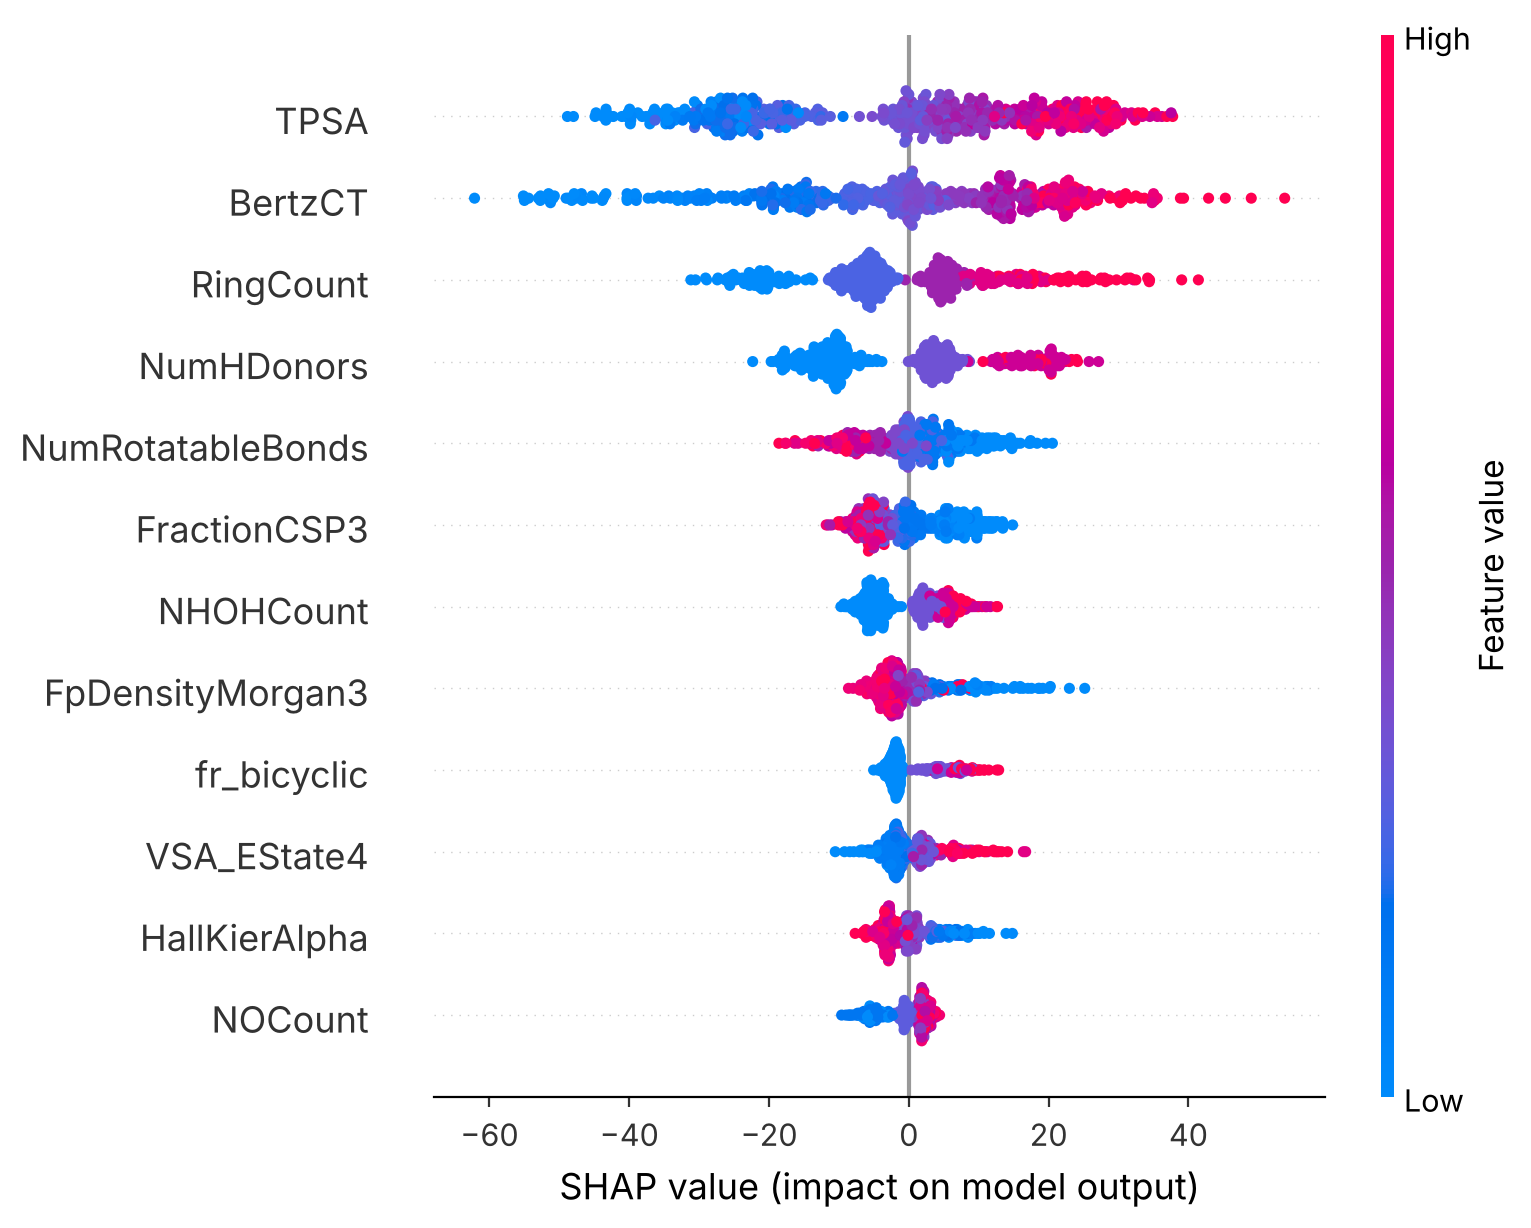

In [7]:
import shap
ex = shap.TreeExplainer(xgb)
sv = ex.shap_values(X['test'])
print('완전성 확인: 평균 예측 + SHAP 합 = 모델 예측 ?',
      np.allclose(ex.expected_value + sv.sum(1), xgb.predict(X['test']), atol=1e-3))
imp['shap'] = np.abs(sv).mean(0)
shap.summary_plot(sv, X['test'], feature_names=names, max_display=12, show=False)
plt.tight_layout(); plt.show()

**읽는 법.** 점 하나 = test 분자 하나. 가로 = 그 분자에서 그 기술자의 SHAP 값(logP 단위), 색 = 기술자 값(빨강 큼, 파랑 작음).
`TPSA`(극성 표면적)가 크면(빨강) 왼쪽(logP 감소)에 있으면 화학 상식과 맞는 것이다.

### a-4. 세 방법의 순위 비교
같은 모델(XGBoost)이어도 permutation 과 SHAP 은 순위가 다를 수 있다. 선형 계수는 다른 모델(Ridge)의 설명이다.

In [8]:
imp['xgb_gain'] = xgb.feature_importances_
cols = ['ridge_abs_coef', 'perm', 'shap', 'xgb_gain']
top = {c: imp.sort_values(c, ascending=False).name.head(10).tolist() for c in cols}
display_top = pd.DataFrame(top); display_top.index += 1
rank_rho = pd.DataFrame([[spearmanr(imp[a], imp[b]).correlation for b in cols] for a in cols], index=cols, columns=cols).round(2)
overlap = pd.DataFrame([[len(set(top[a]) & set(top[b])) for b in cols] for a in cols], index=cols, columns=cols)
print('기술자 전체 순위 Spearman'); print(rank_rho)
print('\n상위 10개 겹치는 수'); print(overlap)
display_top

기술자 전체 순위 Spearman
                ridge_abs_coef  perm  shap  xgb_gain
ridge_abs_coef            1.00  0.45  0.63      0.42
perm                      0.45  1.00  0.75      0.44
shap                      0.63  0.75  1.00      0.56
xgb_gain                  0.42  0.44  0.56      1.00

상위 10개 겹치는 수
                ridge_abs_coef  perm  shap  xgb_gain
ridge_abs_coef              10     3     3         3
perm                         3    10     8         4
shap                         3     8    10         6
xgb_gain                     3     4     6        10


,ridge_abs_coef,perm,shap,xgb_gain
1,TPSA,BertzCT,TPSA,RingCount
2,VSA_EState1,TPSA,BertzCT,NumHDonors
3,FpDensityMorgan2,RingCount,RingCount,TPSA
4,Phi,NumHDonors,NumHDonors,BertzCT
5,Chi1n,NumRotatableBonds,NumRotatableBonds,NOCount
6,NOCount,FractionCSP3,FractionCSP3,NHOHCount
7,BertzCT,HallKierAlpha,NHOHCount,NumAromaticRings
8,Kappa2,HeavyAtomMolWt,FpDensityMorgan3,NumHeterocycles
9,NumHeteroatoms,VSA_EState4,fr_bicyclic,fr_Ar_COO
10,NumRotatableBonds,FpDensityMorgan3,VSA_EState4,fr_bicyclic


### a-5. PDP / ICE
SHAP 상위 기술자 둘에 대해, 그 값만 바꾸고 나머지는 그대로 둘 때 예측이 어떻게 변하는지 그린다.
얇은 선 = 분자 하나 (ICE), 굵은 선 = 평균 (PDP). 선들이 평행하지 않으면 다른 기술자와 상호작용이 있다는 뜻이다.

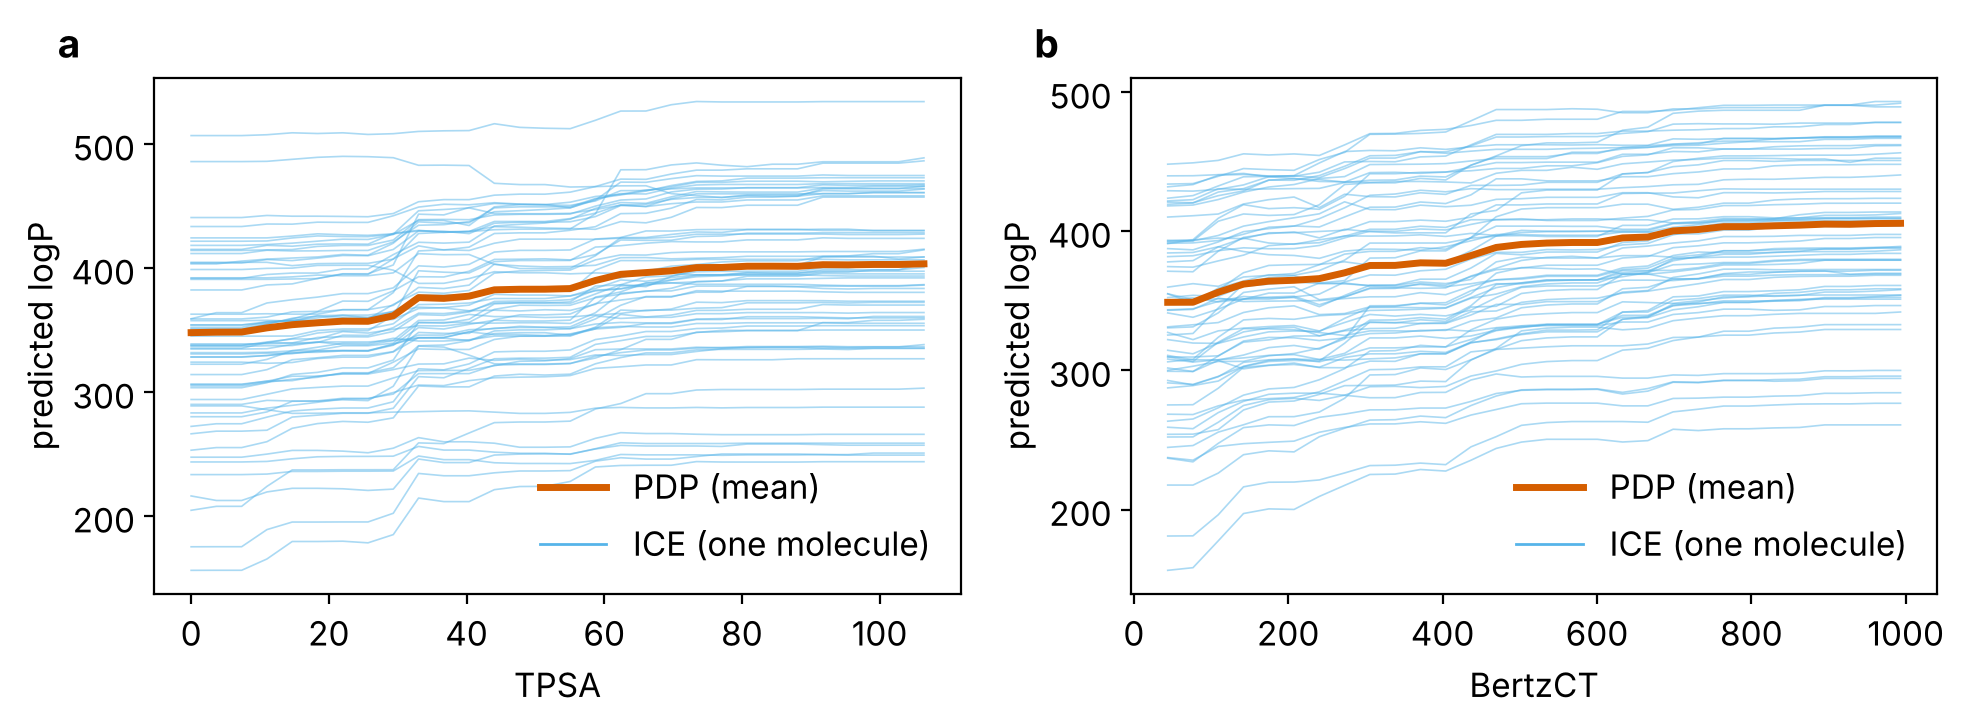

In [9]:
from sklearn.inspection import partial_dependence
top2 = imp.sort_values('shap', ascending=False).index[:2].tolist()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
pdp_store = {}
for ax, j, tag in zip(axes, top2, 'ab'):
    pd_res = partial_dependence(xgb, X['test'], [j], kind='both', grid_resolution=30)
    grid = pd_res['grid_values'][0]; ice = pd_res['individual'][0]; avg = pd_res['average'][0]
    rng = np.random.default_rng(0); sel = rng.choice(len(ice), 60, replace=False)
    for k in sel:
        ax.plot(grid, ice[k], color='#56B4E9', lw=0.6, alpha=0.5)
    ax.plot(grid, avg, color='#D55E00', lw=2.5, label='PDP (mean)')
    ax.plot([], [], color='#56B4E9', lw=1, label='ICE (one molecule)')
    ax.set_xlabel(names[j]); ax.set_ylabel('predicted logP'); ax.legend(frameon=False, loc='best')
    ax.text(-0.12, 1.04, tag, transform=ax.transAxes, fontsize=14, fontweight='bold')
    pdp_store[names[j]] = dict(grid=grid.tolist(), avg=avg.tolist(), ice=ice[sel].tolist())
plt.tight_layout(); plt.show()

## b. Morgan 지문 모델: 비트를 부분구조로 되돌리기
Morgan 비트 하나 = "어떤 원자를 중심으로 반경 r 안의 부분구조"를 해시한 번호다. SHAP 상위 비트를 골라 **어떤 부분구조인지 그림으로** 되돌린다.

In [10]:
XF = {k: morgan_matrix(v) for k, v in smi.items()}
xgb_fp = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.5,
                      n_jobs=8, random_state=SEED).fit(XF['train'], y['train'])
R['MAE']['XGB_morgan'] = mae(xgb_fp.predict(XF['test']), y['test'])
sv_fp = shap.TreeExplainer(xgb_fp).shap_values(XF['test'].astype(float))
bit_imp = np.abs(sv_fp).mean(0)
top_bits = np.argsort(-bit_imp)[:6]
rows = []
for b in top_bits:
    on = XF['test'][:, b] == 1
    frags = bit_fragments(smi['train'], int(b))
    rows.append(dict(bit=int(b), mean_abs_shap=bit_imp[b], shap_when_on=sv_fp[on, b].mean() if on.any() else np.nan,
                     frac_on=on.mean(), n_fragment_kinds=len(frags), top_fragment=list(frags)[0] if frags else ''))
bits = pd.DataFrame(rows).round(3)
print(f"Morgan + XGBoost test MAE = {R['MAE']['XGB_morgan']:.3f}")
bits

Morgan + XGBoost test MAE = 41.009


,bit,mean_abs_shap,shap_when_on,frac_on,n_fragment_kinds,top_fragment
0,1380,16.080999,10.049000,0.798,12,C(arom)
1,807,13.971000,12.380000,0.540,13,C
2,1057,8.589000,-7.319000,0.554,8,C
3,1873,7.131000,4.669000,0.754,12,C(arom)
4,1171,7.114000,29.469000,0.112,19,N
5,314,6.564000,21.705999,0.144,5,C=O


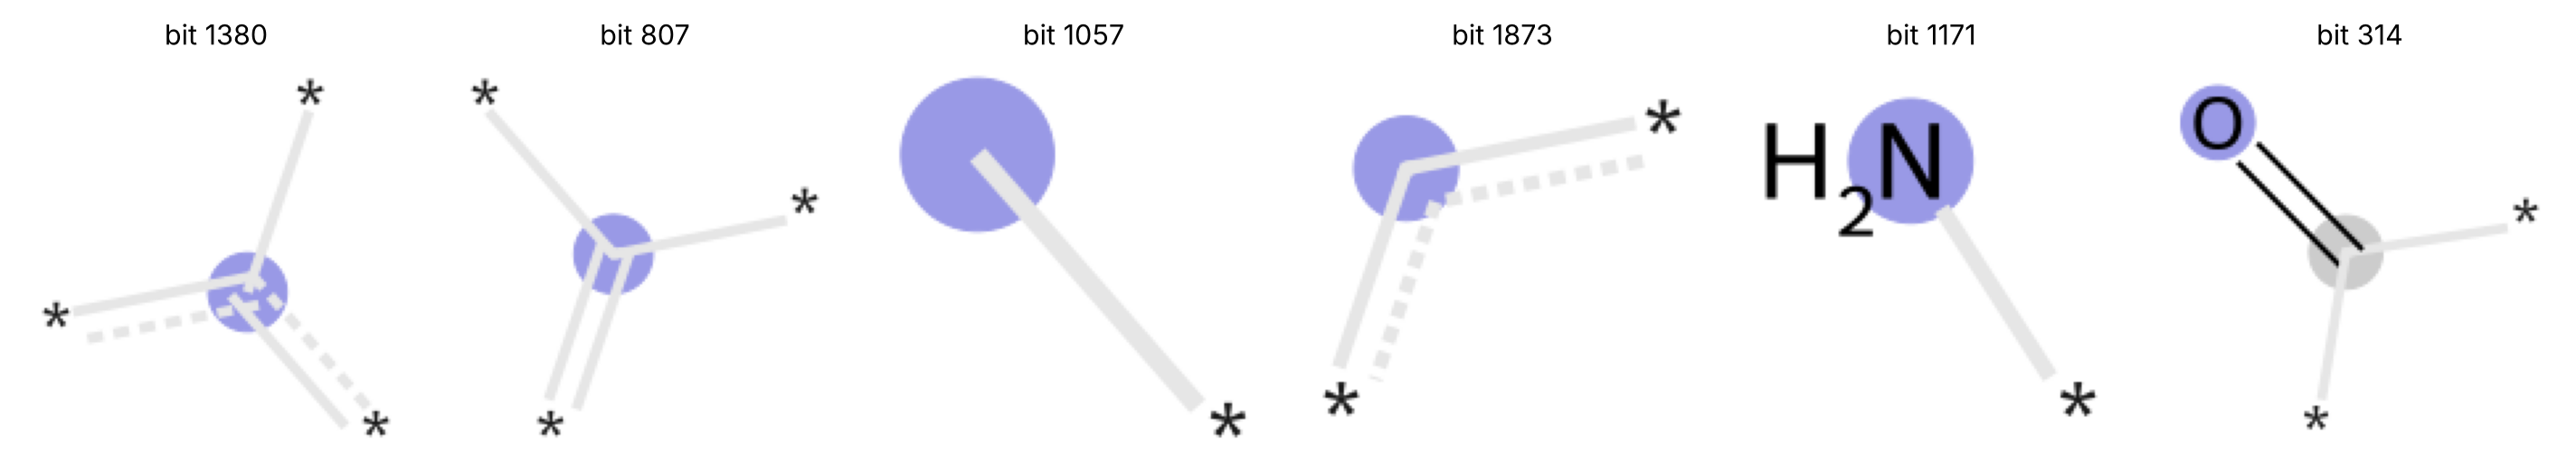

In [11]:
imgs, legends = [], []
for b in top_bits:
    for s in smi['train']:
        m = Chem.MolFromSmiles(s); bi = morgan_bit_info(m)
        if int(b) in bi:
            im = Draw.DrawMorganBit(m, int(b), bi, useSVG=False)
            imgs.append(png_to_array(im) if isinstance(im, bytes) else im); legends.append(f'bit {b}'); break
fig, axes = plt.subplots(1, len(imgs), figsize=(2.4 * len(imgs), 2.6))
for ax, im, lg in zip(axes, imgs, legends):
    ax.imshow(im); ax.set_title(lg, fontsize=11); ax.axis('off')
plt.tight_layout(); plt.show()

**읽는 법.** 파란 원 = 중심 원자, 노란 원 = 방향족 원자, 회색 = 반경 안 원자. `n_fragment_kinds` 가 2 이상이면 서로 다른 부분구조가 **같은 비트**를 켠 것(비트 충돌)이다.
그 비트의 SHAP 값은 여러 부분구조의 효과가 섞인 값이다.

## c. GIN 원자 기여
readout 은 **sum** 으로 한다. logP 처럼 원자 몫을 더해 만드는 물성에 맞고(2주차 0.41 → 0.31), 아래 'readout 분해'가 정확히 성립한다.
`xai.train_gnn` 은 `train.run()` 과 같은 학습 설정(GIN 5층, hidden 128, dropout 0.3, AdamW 1e-3, batch 64)에 모델 객체를 돌려준다.

In [12]:
model, info = train_gnn(sets, scaler, pooling='sum', seed=SEED, epochs=150, patience_stop=20)
R['gin'] = info; R['MAE']['GIN_sum'] = info['test_MAE']
info

  epoch   0  val MAE 59.123  (2 s)


  epoch  20  val MAE 44.199  (34 s)


  epoch  40  val MAE 39.269  (67 s)


  epoch  60  val MAE 37.843  (101 s)


  epoch  80  val MAE 36.003  (133 s)


[train_gnn] seed 42, sum pool: test MAE 38.022, 89 epochs, 147 s


{'seed': 42,
 'pooling': 'sum',
 'epochs': 89,
 'sec': 146.7,
 'val_MAE': 34.9722,
 'test_MAE': 38.0221}

원자 v 의 기여 $a_v$ (특징 147개를 더해 원자 하나에 숫자 하나):

| 방법 | 식 | 부호 | 한 줄 직관 |
|---|---|---|---|
| saliency | $\sum_f \lvert \partial \hat y / \partial x_{vf} \rvert$ | 없음 | 이 원자 특징을 살짝 바꾸면 예측이 얼마나 흔들리나 |
| gradient × input | $\sum_f x_{vf}\, \partial \hat y / \partial x_{vf}$ | 있음 | 1차 테일러 근사의 원자 몫 |
| Integrated Gradients | $\sum_f x_{vf} \int_0^1 \partial \hat y(\alpha x)/\partial x_{vf}\, d\alpha$ | 있음 | 0 에서 x 까지 걸어가며 모은 기울기. 합 = $\hat y(x) - \hat y(0)$ |
| GNNExplainer | 예측을 유지하는 최소 원자 마스크 | 없음 | 원자를 지워도 예측이 같으면 중요하지 않다 |
| readout 분해 | $w \cdot z_v$ | 있음 | sum pool + 선형 head 이면 예측 = 원자 몫의 합 그대로 |

In [13]:
d = sets['test'][0]
ig, chk = attr_integrated_gradients(model, d, return_check=True)
print(d.smiles)
print('IG 완전성: sum IG =', round(chk['sum_IG'], 3), ' F(x) - F(0) =', round(chk['F_x_minus_F_baseline'], 3))
R['ig_completeness'] = chk
methods = {'saliency':     lambda d: attr_saliency(model, d),
           'grad_x_input': lambda d: attr_grad_input(model, d),
           'IG':           lambda d: attr_integrated_gradients(model, d),
           'GNNExplainer': lambda d: attr_gnnexplainer(model, d, epochs=100),
           'readout':      lambda d: attr_readout(model, d),
           'element_rule': lambda d: attr_element_rule(d.smiles),
           'random':       None}
pd.DataFrame({'atom': [a.GetSymbol() for a in Chem.MolFromSmiles(d.smiles).GetAtoms()],
              'Crippen': crippen_atom_contribs(d.smiles),
              **{k: f(d) for k, f in methods.items() if f is not None and k != 'element_rule'}}).round(3)

CC1C(c2ccc(Cl)cc2)SC(=O)N1C(=O)NC1CCCCC1
IG 완전성: sum IG = 16.021  F(x) - F(0) = 16.329


,atom,Crippen,saliency,grad_x_input,IG,GNNExplainer,readout
0,C,0.513,2.722000,-0.128,-0.743,0.339,0.043
1,C,-0.082,6.831000,0.169,1.590,0.590,0.060
2,C,0.242,16.639000,0.185,1.946,0.617,0.059
3,C,0.136,16.735001,0.309,2.205,0.652,0.056
4,C,0.281,18.759001,-0.168,0.052,0.351,0.033
5,C,0.281,7.505000,-0.048,0.128,0.315,-0.005
6,C,0.245,13.048000,0.242,1.612,0.679,-0.020
7,Cl,0.690,2.057000,0.028,0.011,0.663,-0.075
8,C,0.281,7.505000,-0.048,0.128,0.299,-0.005
9,C,0.281,18.759001,-0.168,0.052,0.329,0.033


## d. 설명 검증: Crippen 원자 기여와 순위가 맞나
분자마다 "원자 기여 순위"가 Crippen 순위와 얼마나 같은지 Spearman ρ 로 잰다 (1 = 같은 순위, 0 = 무관, −1 = 반대).
- **random**: 원자마다 무작위 숫자. 설명이 이것보다 못하면 의미가 없다
- **element_rule**: 모델 없이 "C·S·할로젠 +1, N·O −1". 화학 상식 수준이 어디까지 맞는지
- 부호가 없는 방법(saliency, GNNExplainer)은 **|기여| vs |Crippen|** 열도 같이 본다

시간: 분자 200개 × 방법 7개, 약 2분 (GNNExplainer 가 대부분).

In [14]:
t = time.time()
ev, store = evaluate_attributions(model, sets['test'], methods, n=N_EVAL, seed=SEED)
summ = summarize(ev)
R['eval_sec'] = round(time.time() - t, 1); R['eval'] = summ.reset_index().to_dict('records')
print(f'{time.time() - t:.0f} s,  분자 {ev.i.nunique()}개 (원자 6개 이상)')
summ.sort_values('signed_mean', ascending=False)

75 s,  분자 200개 (원자 6개 이상)


,signed_mean,signed_sd,abs_mean,abs_sd,n_mol
method,,,,,
element_rule,0.566,0.187,-0.207,0.405,181
random,-0.009,0.278,-0.017,0.284,200
saliency,-0.146,0.410,-0.096,0.392,200
readout,-0.294,0.378,-0.015,0.372,200
GNNExplainer,-0.309,0.314,-0.128,0.423,200
grad_x_input,-0.353,0.333,-0.019,0.380,200
IG,-0.433,0.323,-0.133,0.408,200


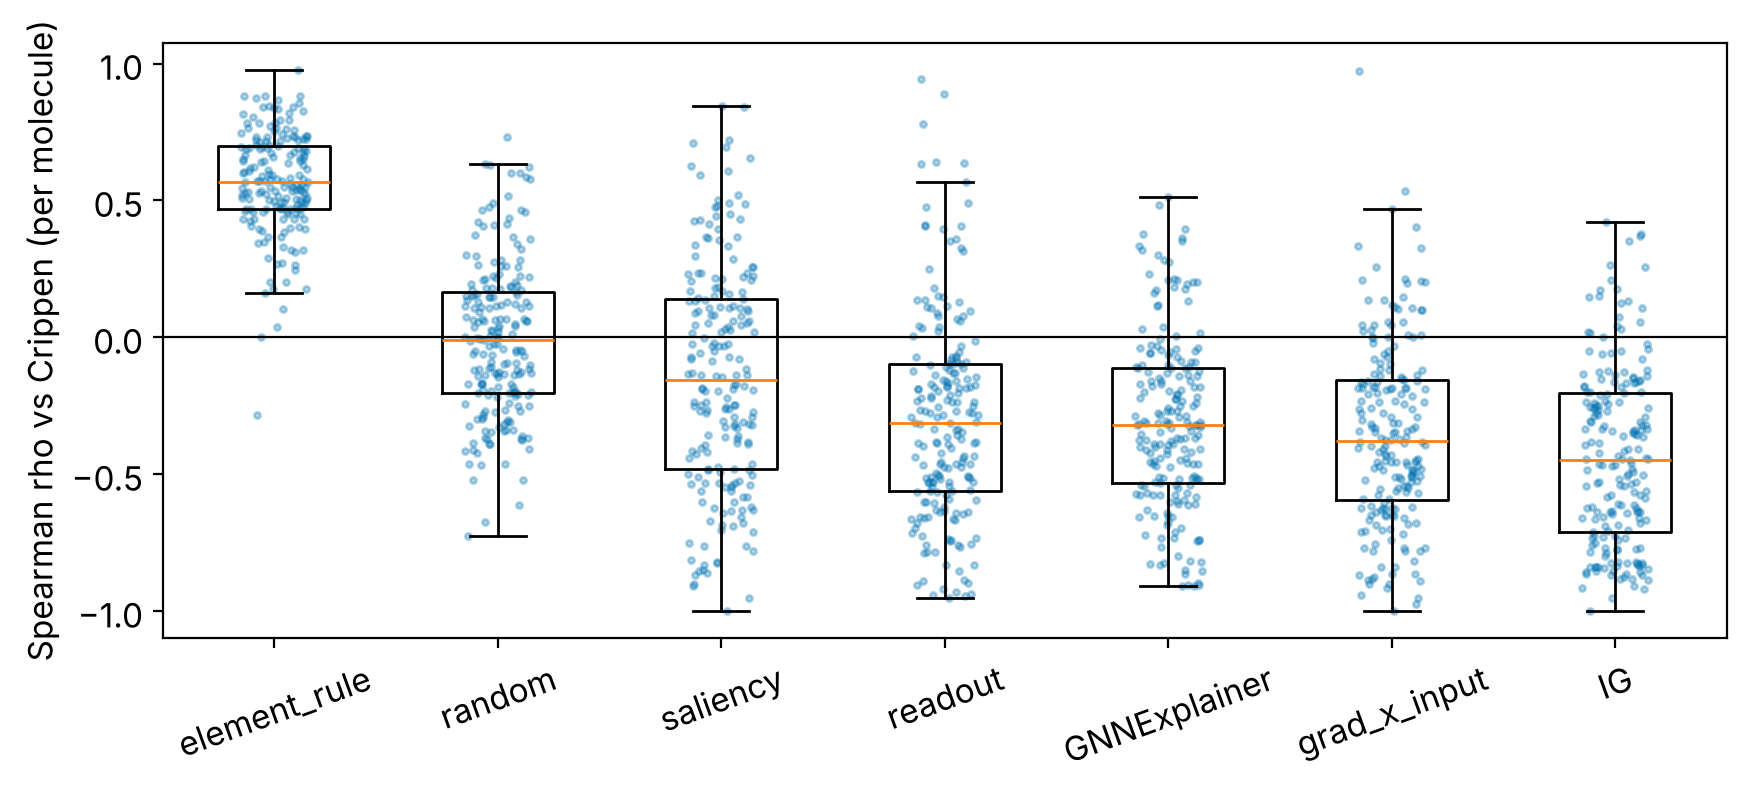

In [15]:
order = summ.sort_values('signed_mean', ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(9, 4))
data = [ev[ev.method == m].rho_signed.dropna().values for m in order]
ax.boxplot(data, showfliers=False); ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order)
for k, v in enumerate(data):
    ax.scatter(np.full(len(v), k + 1) + np.random.default_rng(k).uniform(-0.15, 0.15, len(v)), v, s=5, alpha=0.3, color='#0072B2')
ax.axhline(0, color='k', lw=0.8)
ax.set_ylabel('Spearman rho vs Crippen (per molecule)')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

**같은 4개 분자를 방법별로 그려 보기.** 원자 6–20개 분자 중 IG 의 ρ 가 가장 높은 것, 중간 둘, 가장 낮은 것을 고른다 (잘 맞는 경우와 틀린 경우 모두).
주황 = logP 를 올리는 쪽, 보라 = 내리는 쪽. 분자마다 최댓값으로 정규화했다.

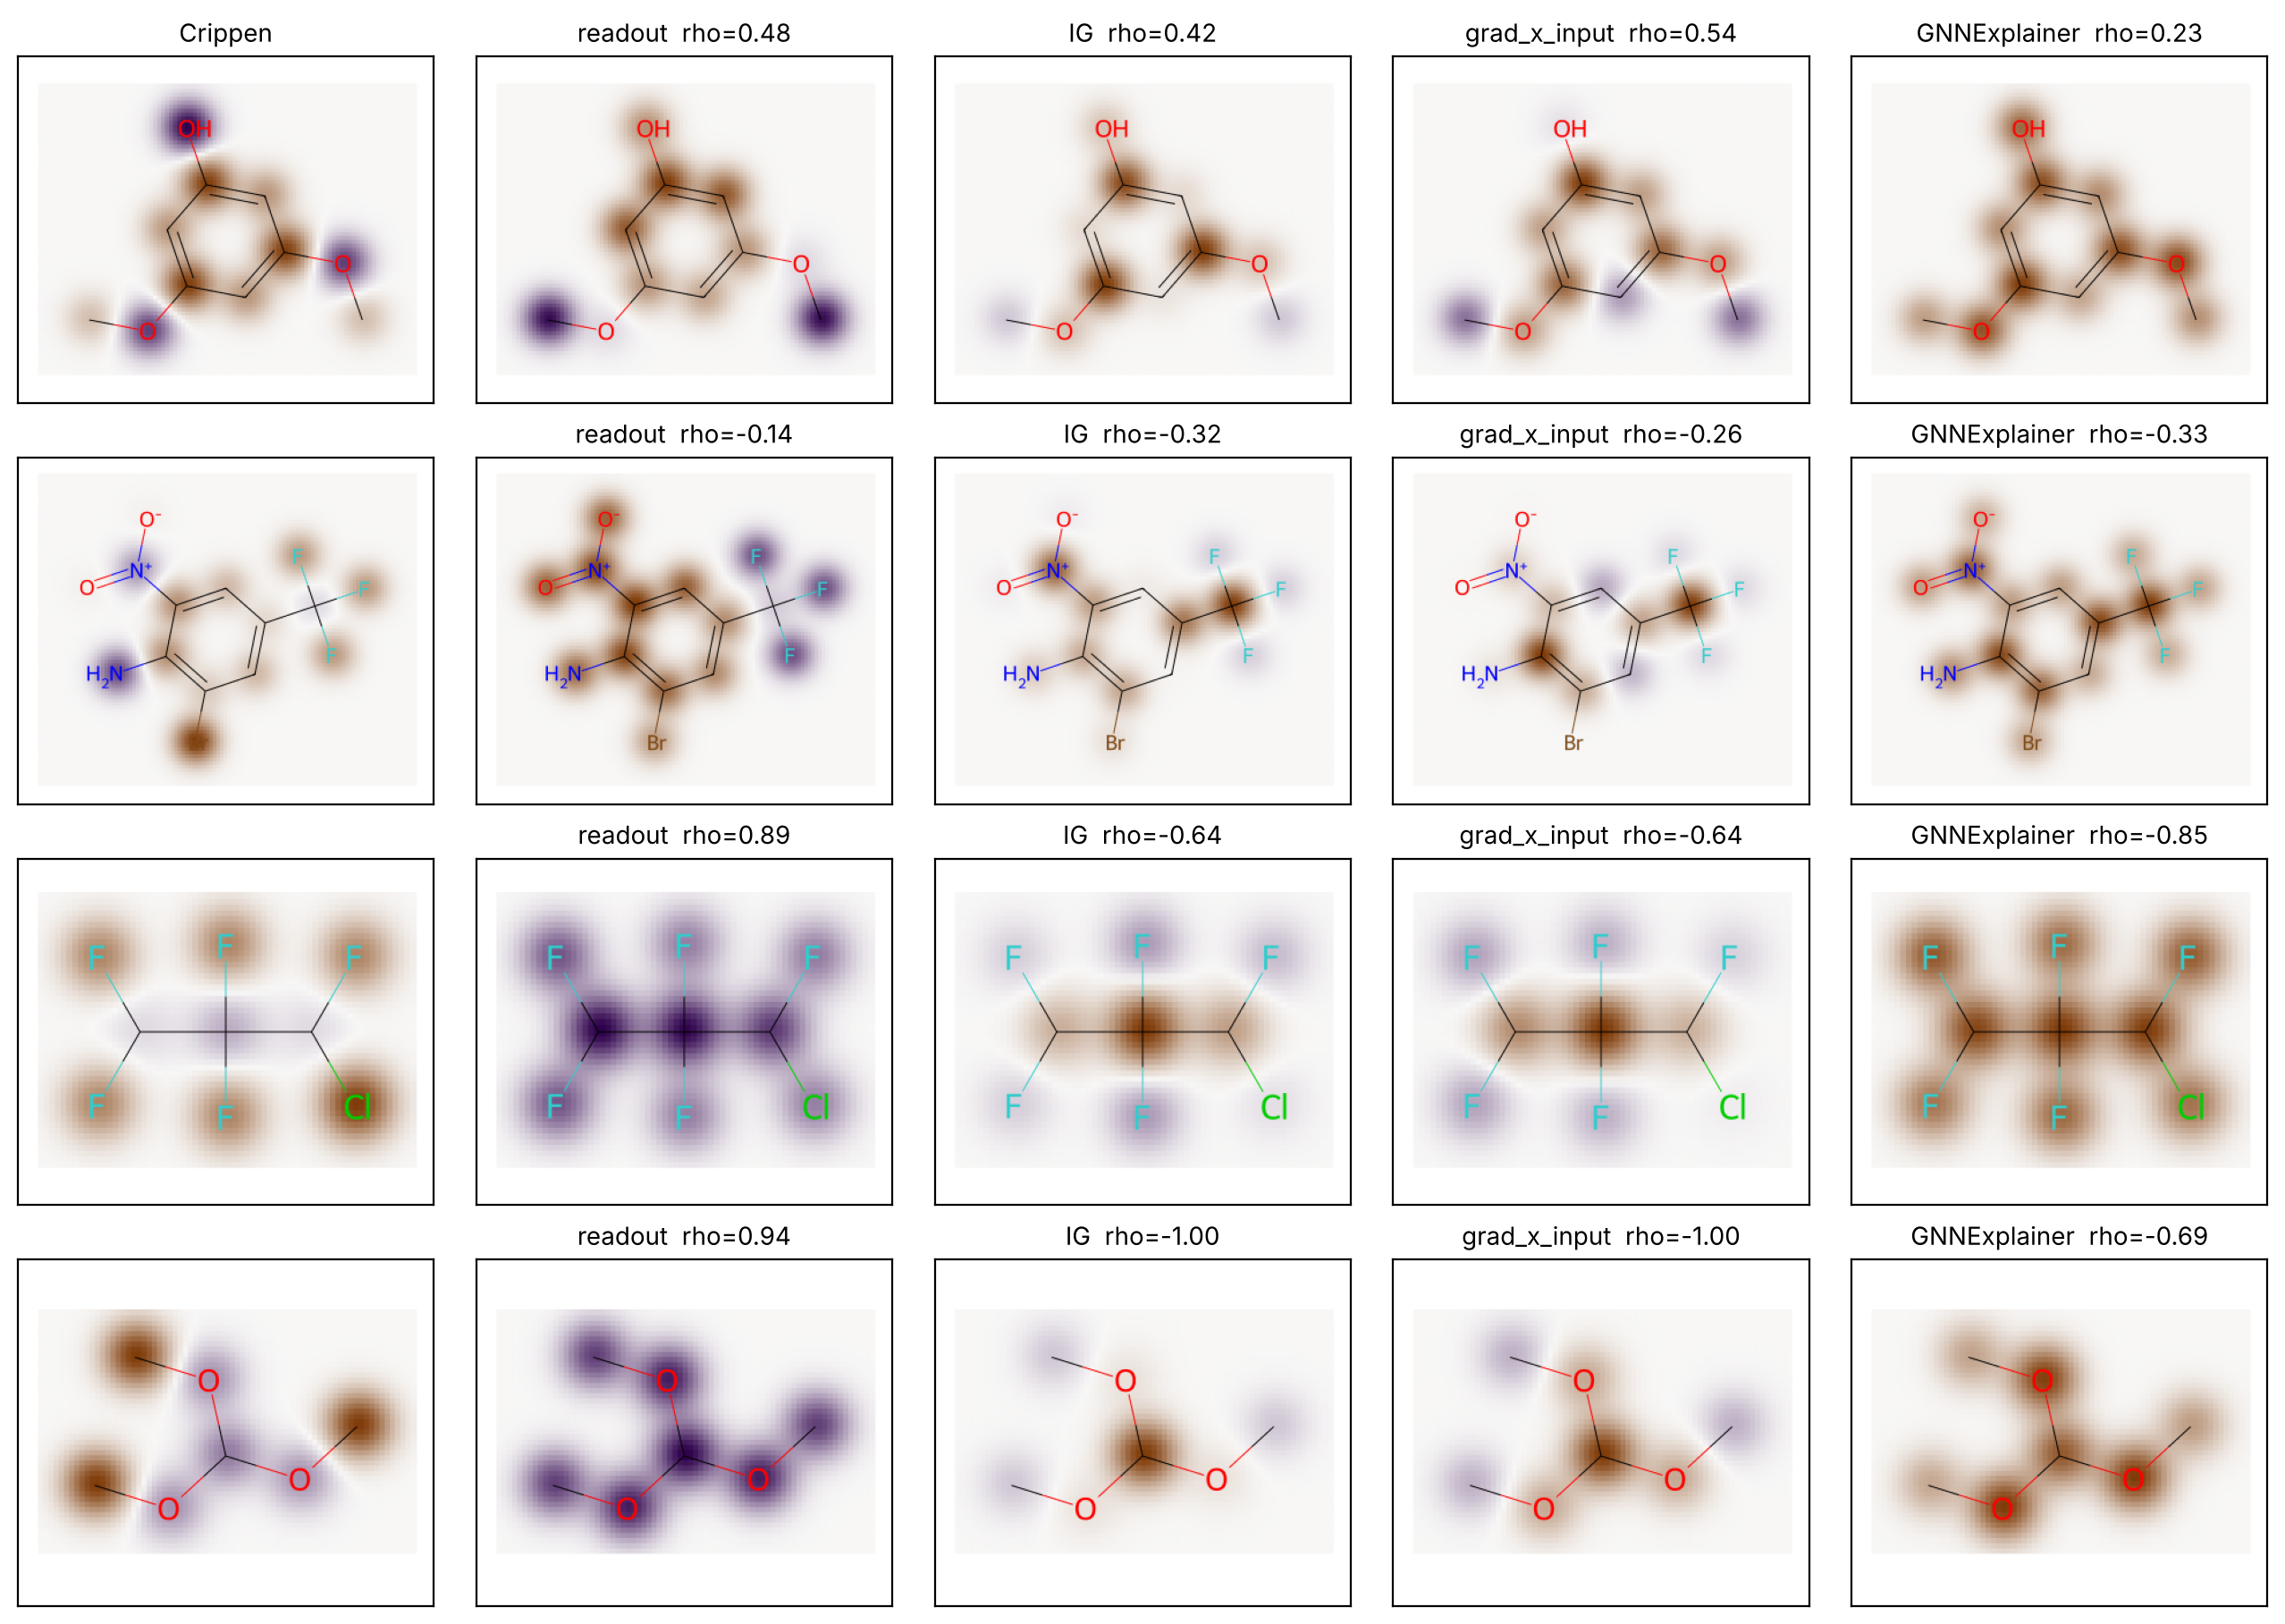

In [16]:
cand = ev[(ev.method == 'IG') & ev.n_atoms.between(6, 20)].dropna().sort_values('rho_signed', ascending=False)
pick = [cand.i.iloc[0], cand.i.iloc[len(cand) // 3], cand.i.iloc[2 * len(cand) // 3], cand.i.iloc[-1]]
show = ['Crippen', 'readout', 'IG', 'grad_x_input', 'GNNExplainer']
fig, axes = plt.subplots(len(pick), len(show), figsize=(2.6 * len(show), 2.3 * len(pick)))
examples = []
for r, k in enumerate(pick):
    s = ev[(ev.i == k)].smiles.iloc[0]
    w = {'Crippen': crippen_atom_contribs(s), **{m: store[(k, m)] for m in show[1:]}}
    examples.append(dict(i=int(k), smiles=s, **{m: np.asarray(v).tolist() for m, v in w.items()},
                         rho={m: float(ev[(ev.i == k) & (ev.method == m)].rho_signed.iloc[0]) for m in show[1:]}))
    for c, m in enumerate(show):
        ax = axes[r, c]; ax.imshow(png_to_array(atom_map_png(s, w[m]))); ax.set_xticks([]); ax.set_yticks([])
        rho = '' if m == 'Crippen' else f"  rho={examples[-1]['rho'][m]:.2f}"
        if r == 0 or m != 'Crippen':
            ax.set_title(m + rho, fontsize=10)
plt.tight_layout(); plt.show()

**sanity check: 학습 안 한 모델 (model randomization test).** 가중치가 무작위인 GIN 으로 같은 계산을 한다.
설명 방법이 모델이 배운 것을 반영한다면 ρ 가 크게 떨어져야 한다. 떨어지지 않으면 그 방법은 **입력(원자 종류)만 보고 있는** 것이다 (Adebayo et al. 2018).

In [17]:
torch.manual_seed(0)
untrained = GraphRegressor(147, 16, conv='GIN', dropout=0.3, pooling='sum').eval()
m_un = {'grad_x_input': lambda d: attr_grad_input(untrained, d), 'IG': lambda d: attr_integrated_gradients(untrained, d),
        'readout': lambda d: attr_readout(untrained, d), 'saliency': lambda d: attr_saliency(untrained, d)}
ev_un, _ = evaluate_attributions(untrained, sets['test'], m_un, n=N_EVAL, seed=SEED)
cmp = pd.DataFrame({'trained': summ.signed_mean, 'untrained': summarize(ev_un).signed_mean}).dropna().round(3)
R['untrained'] = cmp.reset_index().rename(columns={'index': 'method'}).to_dict('records')
cmp

,trained,untrained
method,,
IG,-0.433,-0.065
grad_x_input,-0.353,-0.052
readout,-0.294,-0.106
saliency,-0.146,-0.060


## e. 처음부터 해석되는 모델 (intrinsically interpretable)
사후 설명(post-hoc) 대신 **모델 자체가 설명**인 경우.

1. **원자 기여 선형 모델 (group contribution)**: 분자 벡터 = 원자 특징 147개의 합, 그 위에 Ridge. 원자 v 의 몫 = $x_v \cdot w$ 가 정확한 설명이다.
   화공에서 쓰는 Joback 법, Crippen 법과 같은 형태이고, GIN 을 0층으로 줄인 것과 같다.
2. **얕은 결정나무 (깊이 3)**: 규칙 8개로 끝나서 그림 한 장으로 읽힌다.
3. **KAN (Kolmogorov–Arnold network)**: 연결선마다 1차원 함수(스플라인)를 학습. 가지치기 후 함수 모양을 직접 보거나 식으로 바꿀 수 있다.
   연구실 KAN-DoE 원고(투고 중)는 KAN 의 미분으로 기술자 중요도(average gradient energy)를 계산해 실험 설계에 넣는다. 여기서는 코드 없이 덱에서만 다룬다.

In [18]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
A = {k: np.stack([d.x.sum(0).numpy() for d in v]) for k, v in sets.items()}           # 원자 특징 합 (분자 x 147)
gc = Ridge(alpha=1.0).fit(A['train'], y['train'])
R['MAE']['GroupContrib_Ridge'] = mae(gc.predict(A['test']), y['test'])
tree = DecisionTreeRegressor(max_depth=3, random_state=SEED).fit(X['train'], y['train'])
R['MAE']['Tree_depth3_desc'] = mae(tree.predict(X['test']), y['test'])
R['MAE']['Crippen_MolLogP'] = R['crippen_test_MAE']

w = gc.coef_
gc_rho = [rank_agreement(d.x.numpy() @ w, crippen_atom_contribs(d.smiles))
          for d in [d for d in sets['test'] if d.x.shape[0] >= 6][:N_EVAL]]
R['group_contrib_rho'] = dict(mean=float(np.nanmean(gc_rho)), sd=float(np.nanstd(gc_rho, ddof=1)))
print(f"group contribution 원자 몫 vs Crippen: rho = {np.nanmean(gc_rho):.3f} ± {np.nanstd(gc_rho, ddof=1):.3f}")
pd.Series(R['MAE']).sort_values().round(3).to_frame('test MAE')

group contribution 원자 몫 vs Crippen: rho = -0.424 ± 0.390


,test MAE
XGB_desc,33.132
GIN_sum,38.022
Ridge_desc,39.447
XGB_morgan,41.009
GroupContrib_Ridge,44.734
Tree_depth3_desc,49.142
Crippen_MolLogP,372.694


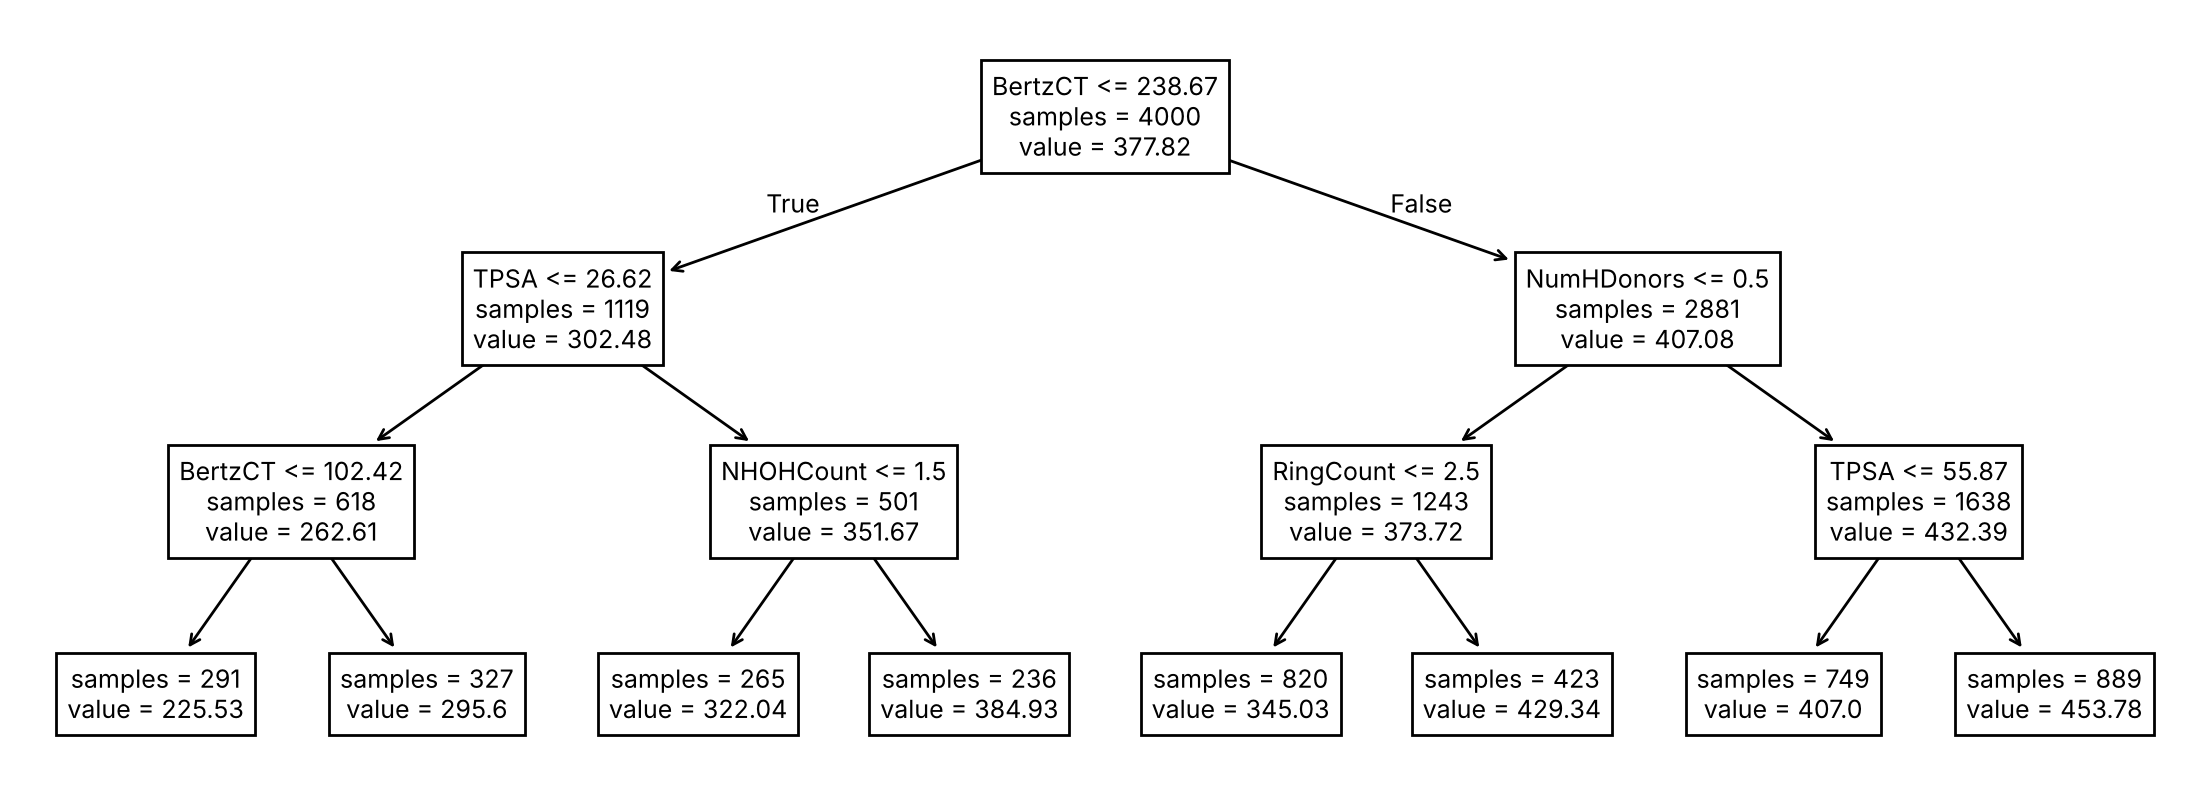

원자 특징 계수 (logP / 원자, 원자 2% 이상에서 켜지는 칸만) 상위 +, 하위 -
numH=0                            78.504997
FG:Hydrogen-bond donor#1          62.476002
FG:Carboxylic acid                54.575001
numH=1                            52.877998
numH=2                            34.658001
valence=2                         26.986000
degree=1                         -63.208000
FG:Divalent Oxygen               -49.488998
valence=3                        -37.515999
degree=2                         -35.005001
FG:Hydroxyl in Carboxylic Acid   -32.860001
hybrid=SP2                       -27.344999
dtype: float32
원소 칸: {'element=C': -4.296000003814697, 'element=N': 3.8299999237060547, 'element=O': -8.590999603271484}


In [19]:
fig, ax = plt.subplots(figsize=(14, 5))
plot_tree(tree, feature_names=names, filled=False, impurity=False, precision=2, fontsize=9, ax=ax)
plt.show()
from feature import NODE_FEATURE_NAMES
freq = np.concatenate([d.x.numpy() for d in sets['train']]).mean(0)            # 학습 원자 중 그 칸이 1인 비율
gcw = pd.Series(w, index=NODE_FEATURE_NAMES)[freq >= 0.02]                       # 드문 칸(원자 2% 미만)은 계수가 불안정해서 뺀다
gc_top = pd.concat([gcw.nlargest(6), gcw.nsmallest(6)]).round(3)
print('원자 특징 계수 (logP / 원자, 원자 2% 이상에서 켜지는 칸만) 상위 +, 하위 -'); print(gc_top)
print('원소 칸:', gcw[[n for n in gcw.index if n.startswith('element=')]].round(3).to_dict())
R['gc_top'] = {k: float(v) for k, v in gc_top.items()}
R['gc_elements'] = {k: float(v) for k, v in gcw[[n for n in gcw.index if n.startswith('element=')]].items()}

## f. 함정 셋
### f-1. 상관된 기술자는 중요도를 나눠 가진다
SHAP 1위 기술자를 그대로 복사한 열(작은 잡음만 추가)을 하나 더 넣고 다시 학습한다. 모델 성능은 같은데 중요도가 두 열로 갈라진다.

In [20]:
j = imp.shap.idxmax(); rng = np.random.default_rng(0)
dup = {k: np.c_[v, v[:, j] + 1e-3 * v[:, j].std() * rng.standard_normal(len(v))] for k, v in X.items()}
xgb_dup = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.5,
                       n_jobs=8, random_state=SEED).fit(dup['train'], y['train'])
sv_dup = np.abs(shap.TreeExplainer(xgb_dup).shap_values(dup['test'])).mean(0)
R['dup'] = dict(feature=names[j], before=float(imp.shap[j]), after_original=float(sv_dup[j]), after_copy=float(sv_dup[-1]),
                MAE_before=R['MAE']['XGB_desc'], MAE_after=mae(xgb_dup.predict(dup['test']), y['test']))
R['dup']

{'feature': 'TPSA',
 'before': 18.494976043701172,
 'after_original': 12.759417533874512,
 'after_copy': 9.64486026763916,
 'MAE_before': 33.132328033447266,
 'MAE_after': 33.58731460571289}

### f-2. SHAP ≠ 인과
SHAP 은 **이 모델이** 그 기술자 값에 얼마나 반응했는지다. 분자에서 그 기술자만 바꾸는 실험이 불가능한 경우가 많고(`TPSA` 를 바꾸면 원자 수도 바뀐다),
상관된 기술자 중 무엇이 원인인지는 데이터로 가를 수 없다. "TPSA 를 줄이면 logP 가 오른다"는 화학 지식이 따로 있을 때만 맞는 말이다.

### f-3. seed 를 바꾸면 설명이 바뀐다
같은 데이터·같은 설정에서 seed 만 바꿔 다시 학습하고, 설명끼리 순위가 얼마나 같은지 본다.

In [21]:
xgb2 = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.5,
                    n_jobs=8, random_state=SEED + 1).fit(X['train'], y['train'])
shap2 = np.abs(shap.TreeExplainer(xgb2).shap_values(X['test'])).mean(0)
t10a, t10b = set(np.argsort(-imp.shap.values)[:10]), set(np.argsort(-shap2)[:10])
R['seed_xgb'] = dict(rho_all=float(spearmanr(imp.shap, shap2).correlation), top10_overlap=len(t10a & t10b),
                     MAE_seed2=mae(xgb2.predict(X['test']), y['test']))
print('XGBoost seed 42 vs 43:', R['seed_xgb'])

model2, info2 = train_gnn(sets, scaler, pooling='sum', seed=7, epochs=150, patience_stop=20)
R['gin_seed2'] = info2
pool = [d for d in sets['test'] if d.x.shape[0] >= 6][:N_EVAL]
seed_rows = []
for d in pool:
    ref = crippen_atom_contribs(d.smiles)
    for name, f in [('IG', attr_integrated_gradients), ('readout', attr_readout), ('grad_x_input', attr_grad_input)]:
        a1, a2 = f(model, d), f(model2, d)
        seed_rows.append(dict(method=name, rho_seed=rank_agreement(a1, a2), rho_crippen_seed2=rank_agreement(a2, ref)))
seed_df = pd.DataFrame(seed_rows).groupby('method').agg(['mean', 'std']).round(3)
R['seed_gin'] = {m: dict(rho_seed_mean=float(seed_df.loc[m, ('rho_seed', 'mean')]), rho_seed_sd=float(seed_df.loc[m, ('rho_seed', 'std')]),
                         rho_crippen_seed2=float(seed_df.loc[m, ('rho_crippen_seed2', 'mean')])) for m in seed_df.index}
seed_df

XGBoost seed 42 vs 43: {'rho_all': 0.9802616605738182, 'top10_overlap': 9, 'MAE_seed2': 34.145687103271484}


  epoch   0  val MAE 72.363  (2 s)


  epoch  20  val MAE 41.442  (34 s)


  epoch  40  val MAE 40.745  (67 s)


  epoch  60  val MAE 36.078  (101 s)


  epoch  80  val MAE 36.286  (135 s)


  epoch 100  val MAE 35.914  (169 s)


[train_gnn] seed 7, sum pool: test MAE 37.368, 105 epochs, 176 s


rho_seed        rho_crippen_seed2       
                 mean    std              mean    std
method                                               
IG              0.802  0.159            -0.380  0.384
grad_x_input    0.676  0.266            -0.363  0.314
readout         0.903  0.180            -0.244  0.384

## g. 팀 과제 (5주차 축 선택과 연결)
**축 E (해석)**
1. 팀 물성으로 a 절을 돌려 SHAP 상위 10개를 표로 낸다. 화학적으로 말이 되는 것 / 안 되는 것을 나눈다
2. 팀 물성에 원자·작용기 기여 정답이 있는지 찾는다 (예: 끓는점·임계물성 Joback 기여). 있으면 d 절처럼 Spearman 으로 GIN 설명을 검증한다
3. 설명 방법 하나를 골라 seed 3개로 다시 돌리고 순위 일치도를 보고한다. 일치도가 낮으면 그 설명으로 결론을 내지 않는다

**축 B (물리 결합)**
4. e 절의 group contribution 모델을 팀 물성에 맞춰 본다. GIN 과 MAE 차이가 얼마인지, 그 차이를 메우는 것이 물리 항(예: logS = f(logP, mp))인지 확인한다

**규칙**: 설명 그림을 결과로 쓸 때는 (i) 무작위 기준선, (ii) 학습 안 한 모델, (iii) seed 2개 이상을 같이 보고한다.

In [22]:
os.makedirs('results_xai', exist_ok=True)
R['runtime_sec'] = round(time.time() - T0, 1)
imp.to_csv('results_xai/desc_importance.csv', index=False)
bits.to_csv('results_xai/morgan_top_bits.csv', index=False)
ev.to_csv('results_xai/rho_per_molecule.csv', index=False)
np.savez_compressed('results_xai/shap_desc.npz', sv=sv, X=X['test'], names=np.array(names))
json.dump(dict(R=R, examples=examples, pdp=pdp_store, top_bits=[int(b) for b in top_bits],
               rank_rho=rank_rho.to_dict(), overlap=overlap.to_dict(), top10=top),
          open('results_xai/xai_summary.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1, default=float)
print(f"전체 {R['runtime_sec']:.0f} s")

전체 625 s


# [추가] mp 전용 확장 (교수님 셀 끝, 여기부터는 팀 추가)

| 절 | 내용 | 원본 노트북과의 관계 |
|---|---|---|
| X1 | **Joback Tm** (Joback & Reid 1987) = mp 의 원자 가산 '참고 답'. test MAE 와 덮임률 | Crippen 의 mp 판 (0절·e절 대체) |
| X2 | SHAP 상위 10 표 (방향·permutation 순위), scaffold 분할, 기술자 217개 판 | 과제: SHAP 상위 10 + 화학 해석 |
| X3 | 설명 검증: GIN 원자 기여 vs Joback 원자 기여 (학습 / 학습 안 한 모델 / 무작위) | d 절의 mp 판 |
| X4 | 화학 점검: 수소결합 공여 원자(N–H, O–H)의 기여 부호 | mp 전용 |
| X5 | seed 3개 (GIN 42 · 7 · 123, XGBoost 42 · 43 · 44) 순위 일치도 | 과제 여유: 축 E |
| X6 | 설명이 틀린 분자 후보 표 + 그림 | 과제: 설명이 틀린 분자 2개 |
| X7 | 1주차 가설 확인 (validate): sum vs mean readout, 작은·비고리 분자 | 1주차 xai_notes 4절 |

규칙 (README 4절): 설명 그림을 결과로 쓸 때 무작위 기준선, 학습 안 한 모델, seed 2개 이상을 같이 본다. 고르는 일은 validate 로.


In [23]:
# X0. 준비
import mp_xai_ext as mx
from rdkit.Chem import Descriptors
OUTX = 'results_xai_mp_ext'; os.makedirs(OUTX, exist_ok=True)
RX = {}                                   # 확장 결과 숫자 모음
torch.save(model.state_dict(), f'{OUTX}/gin_sum_seed{SEED}.pt'); torch.save(model2.state_dict(), f'{OUTX}/gin_sum_seed7.pt')
print('저장:', os.listdir(OUTX))


저장: ['gin_sum_seed7.pt', 'X1_joback_vs_gin_parity.png', 'X3_rho_vs_joback_boxplot.png', 'X2_shap_top10_compare.csv', 'X3_rho_vs_joback_per_molecule.csv', 'X1_mae_with_joback.csv', 'gin_sum_seed42.pt', 'X2_shap_top10_random_189desc.csv', 'X4_hbond_donor_check.csv', 'X2_shap_top10_random_217desc.csv', 'X3_rho_vs_joback_summary.csv', 'X2_shap_top10_scaffold_189desc.csv']


## X1. Joback Tm: mp 의 '원자 가산 참고 답'
Joback 법: $T_m = 122.5\,\mathrm{K} + \sum_g n_g\,\Delta T_{m,g}$ (작용기 41종). 작용기 하나가 원자 하나(대부분)나 여러 원자(–COOH, –NO₂ …)를 덮는다 → 원자마다 ΔTm 몫을 나눌 수 있다 (여러 원자 작용기는 똑같이 나눔).
Crippen 이 logP 에서 맡은 역할과 같지만, **녹는점은 결정 패킹·대칭이 커서 가산법이 약하다** (Joback 원 논문 388개에서 평균 오차 22.6 K, 넓은 데이터에서는 더 큼). 그래서 '정답'이 아니라 '참고 답'이다.


In [24]:
t = time.time()
jb = {k: [mx.joback_atom_contribs(s) for s in v] for k, v in smi.items()}
jb_ok = {k: np.array([ok for _, ok in v]) for k, v in jb.items()}
jb_tm = {k: np.array([mx.TM0 + a.sum() if ok else np.nan for a, ok in v]) for k, v in jb.items()}
okt = jb_ok['test']
RX['joback'] = dict(coverage={k: float(v.mean()) for k, v in jb_ok.items()},
                    test_MAE_covered=float(np.nanmean(np.abs(jb_tm['test'] - y['test']))),
                    test_bias_covered=float(np.nanmean(jb_tm['test'] - y['test'])),
                    n_test_covered=int(okt.sum()), sec=round(time.time() - t, 1))
# 같은 (덮인) test 분자에서 모델들과 비교
pred = {'평균값 (train 평균)': np.full(len(y['test']), y['train'].mean()),
        'Joback Tm (피팅 없음)': jb_tm['test'],
        'Ridge + 기술자': ridge.predict(X['test']), 'XGBoost + 기술자': xgb.predict(X['test']),
        'XGBoost + Morgan': xgb_fp.predict(XF['test']), 'GIN sum (seed 42)': predict_gnn(model, sets['test'], scaler),
        '원자 가산 Ridge (e절)': gc.predict(A['test']), '결정나무 깊이 3': tree.predict(X['test'])}
tab = pd.DataFrame({'test MAE [K] (전체 test)': {k: np.nanmean(np.abs(v - y['test'])) for k, v in pred.items()},
                    f'test MAE [K] (Joback 덮인 {okt.sum()}개)': {k: np.nanmean(np.abs(v[okt] - y['test'][okt])) for k, v in pred.items()}}).round(1)
tab.loc['Joback Tm (피팅 없음)', 'test MAE [K] (전체 test)'] = np.nan
tab.to_csv(f'{OUTX}/X1_mae_with_joback.csv'); RX['mae_table'] = tab.reset_index().to_dict('records')
print(RX['joback']); tab.sort_values(tab.columns[1])


{'coverage': {'train': 0.8255, 'validate': 0.832, 'test': 0.84}, 'test_MAE_covered': 108.1439301481701, 'test_bias_covered': 89.62212254260835, 'n_test_covered': 420, 'sec': 1.3}


,test MAE [K] (전체 test),test MAE [K] (Joback 덮인 420개)
XGBoost + 기술자,33.1,32.6
GIN sum (seed 42),38.0,38.4
Ridge + 기술자,39.4,39.5
XGBoost + Morgan,41.0,39.7
원자 가산 Ridge (e절),44.7,45.4
결정나무 깊이 3,49.1,50.7
평균값 (train 평균),75.2,75.6
Joback Tm (피팅 없음),NaN,108.1


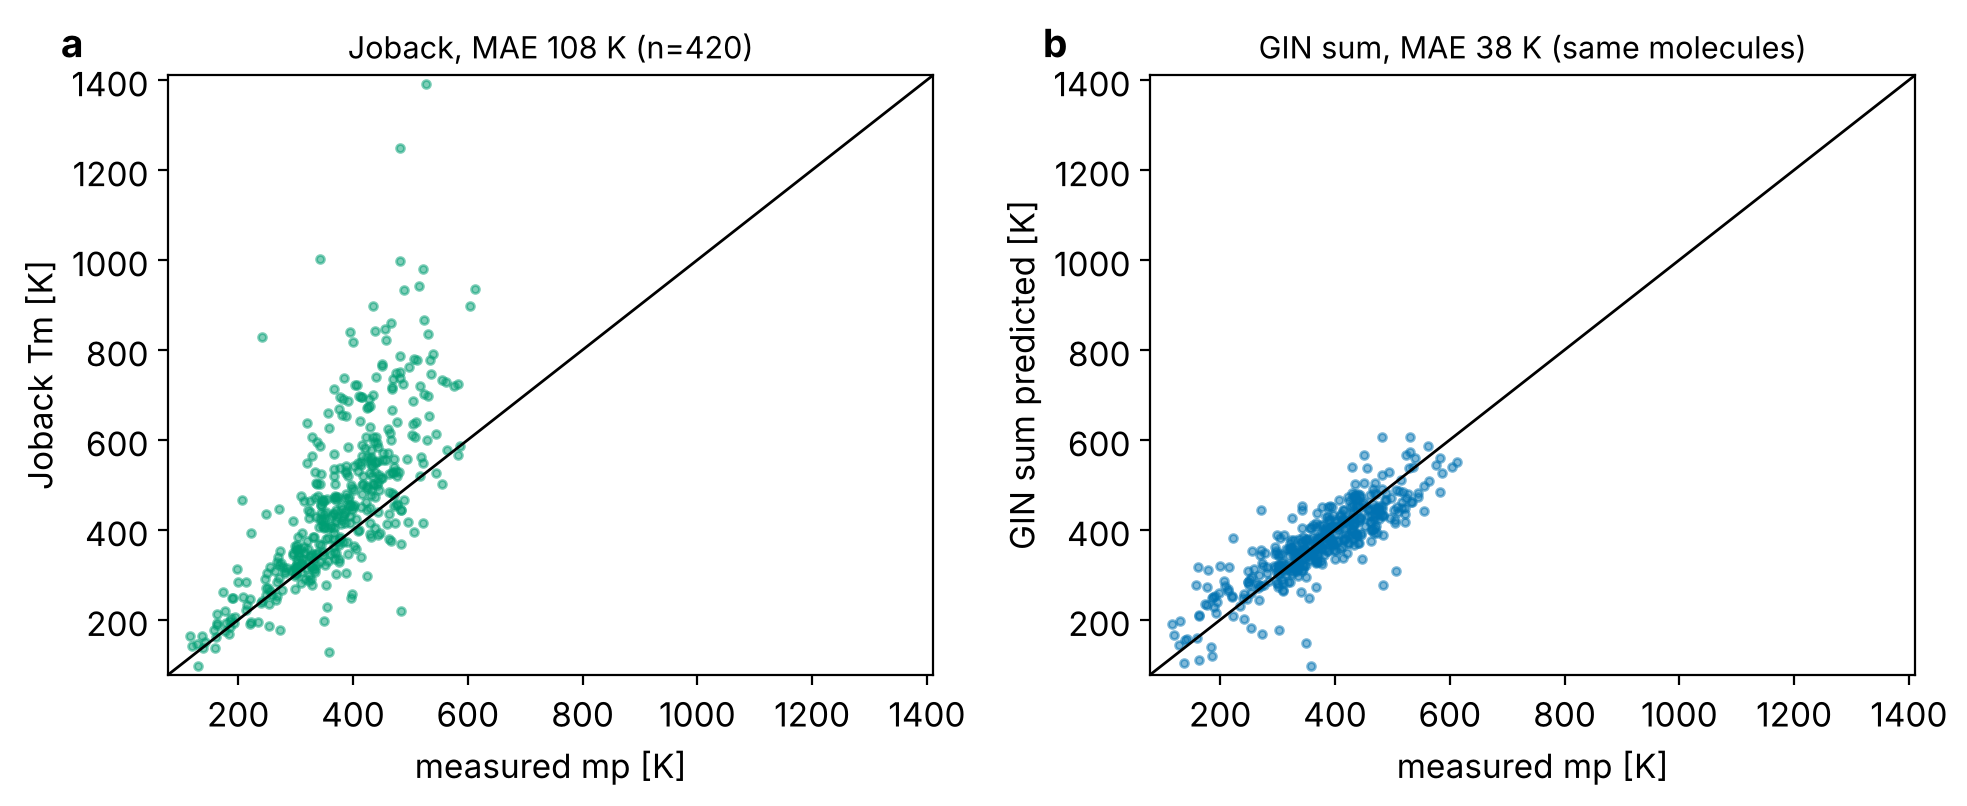

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
yt, jt = y['test'][okt], jb_tm['test'][okt]
lim = (min(yt.min(), jt.min()) - 20, max(yt.max(), jt.max()) + 20)
axes[0].scatter(yt, jt, s=8, alpha=0.5, color='#009E73'); axes[0].plot(lim, lim, 'k', lw=1)
axes[0].set_xlim(lim); axes[0].set_ylim(lim); axes[0].set_xlabel('measured mp [K]'); axes[0].set_ylabel('Joback Tm [K]')
axes[0].set_title(f"Joback, MAE {np.mean(np.abs(jt - yt)):.0f} K (n={okt.sum()})", fontsize=11)
gp_ = pred['GIN sum (seed 42)'][okt]
axes[1].scatter(yt, gp_, s=8, alpha=0.5, color='#0072B2'); axes[1].plot(lim, lim, 'k', lw=1)
axes[1].set_xlim(lim); axes[1].set_ylim(lim); axes[1].set_xlabel('measured mp [K]'); axes[1].set_ylabel('GIN sum predicted [K]')
axes[1].set_title(f"GIN sum, MAE {np.mean(np.abs(gp_ - yt)):.0f} K (same molecules)", fontsize=11)
for ax, tag in zip(axes, 'ab'): ax.text(-0.14, 1.03, tag, transform=ax.transAxes, fontsize=14, fontweight='bold')
plt.tight_layout(); fig.savefig(f'{OUTX}/X1_joback_vs_gin_parity.png', dpi=150); plt.show()


## X2. SHAP 상위 10 (과제 표)
- mean|SHAP| [K] = 그 기술자가 예측을 평균 몇 K 움직였나. 방향 = corr(기술자 값, SHAP) 부호 (+ 이면 값↑ → 예측 mp↑)
- 같은 모델로 permutation 순위, 다른 분할(scaffold), 다른 기술자 집합(217개 = 1주차와 같음)에서 순위가 유지되는지 같이 본다


In [26]:
def shap_table(model_, Xte, names_, k=10):
    s = shap.TreeExplainer(model_).shap_values(Xte)
    m = np.abs(s).mean(0)
    corr = [np.corrcoef(Xte[:, j], s[:, j])[0, 1] if np.std(Xte[:, j]) > 0 and np.std(s[:, j]) > 0 else np.nan for j in range(Xte.shape[1])]
    df = pd.DataFrame({'descriptor': names_, 'mean_abs_SHAP_K': m, 'corr_value_SHAP': corr})
    df['direction'] = np.where(df.corr_value_SHAP > 0.3, '값↑ → mp↑', np.where(df.corr_value_SHAP < -0.3, '값↑ → mp↓', '혼재'))
    df = df.sort_values('mean_abs_SHAP_K', ascending=False).reset_index(drop=True); df.index += 1
    return df, s

top_rand, _ = shap_table(xgb, X['test'], names)
perm_rank = imp.set_index('name').perm.rank(ascending=False)
top_rand['perm_rank'] = top_rand.descriptor.map(perm_rank).astype(int)
top_rand.head(10).round(3).to_csv(f'{OUTX}/X2_shap_top10_random_189desc.csv')
top_rand.head(10).round(3)


,descriptor,mean_abs_SHAP_K,corr_value_SHAP,direction,perm_rank
1,TPSA,18.495001,0.857,값↑ → mp↑,2
2,BertzCT,16.903000,0.873,값↑ → mp↑,1
3,RingCount,11.082000,0.953,값↑ → mp↑,3
4,NumHDonors,10.796000,0.894,값↑ → mp↑,4
5,NumRotatableBonds,5.595000,-0.692,값↑ → mp↓,5
6,FractionCSP3,5.090000,-0.812,값↑ → mp↓,6
7,NHOHCount,4.759000,0.856,값↑ → mp↑,16
8,FpDensityMorgan3,3.631000,-0.835,값↑ → mp↓,10
9,fr_bicyclic,3.050000,0.800,값↑ → mp↑,26
10,VSA_EState4,2.948000,0.891,값↑ → mp↑,9


In [27]:
# scaffold 분할 (같은 5,000개, 같은 기술자) — 순위가 분할에 따라 흔들리나
t = time.time()
sets_s, scaler_s = prepare_graphs(PROP, max_n=MAX_N, seed=SEED, split='scaffold')
row_of = {s: i for i, s in enumerate(smi['train'] + smi['validate'] + smi['test'])}
X_all = np.vstack([X['train'], X['validate'], X['test']]); y_all = np.r_[y['train'], y['validate'], y['test']]
idx_s = {k: np.array([row_of[d.smiles] for d in v]) for k, v in sets_s.items()}
xgb_s = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.5,
                     n_jobs=2, random_state=SEED).fit(X_all[idx_s['train']], y_all[idx_s['train']])
RX['xgb_desc_scaffold_MAE'] = mae(xgb_s.predict(X_all[idx_s['test']]), y_all[idx_s['test']])
top_scaf, _ = shap_table(xgb_s, X_all[idx_s['test']], names)
top_scaf.head(10).round(3).to_csv(f'{OUTX}/X2_shap_top10_scaffold_189desc.csv')
print(f"XGBoost + 기술자 189, scaffold test MAE = {RX['xgb_desc_scaffold_MAE']:.1f} K  ({time.time() - t:.0f} s)")
top_scaf.head(10).round(3)


[load_data] mp: 5,000 rows, unit = K


[gen_dataset] 5,000 graphs, node features = 147, edge features = 16


[split_dataset:scaffold] train 4,000 / validate 500 / test 500


XGBoost + 기술자 189, scaffold test MAE = 36.7 K  (15 s)


,descriptor,mean_abs_SHAP_K,corr_value_SHAP,direction
1,TPSA,18.882000,0.757,값↑ → mp↑
2,BertzCT,17.558001,0.774,값↑ → mp↑
3,RingCount,14.977000,0.895,값↑ → mp↑
4,NumHDonors,10.200000,0.773,값↑ → mp↑
5,NumRotatableBonds,7.613000,-0.839,값↑ → mp↓
6,FractionCSP3,7.021000,-0.834,값↑ → mp↓
7,fr_bicyclic,3.931000,0.828,값↑ → mp↑
8,NHOHCount,3.816000,0.786,값↑ → mp↑
9,VSA_EState3,3.662000,0.602,값↑ → mp↑
10,VSA_EState4,3.153000,0.759,값↑ → mp↑


In [28]:
# 기술자 217개 전부 (1주차와 같은 집합; mp 에서는 Crippen 계열이 누수가 아니다)
t = time.time()
X217 = {k: descriptor_matrix(v, drop_crippen=False)[0] for k, v in smi.items()}
names217 = descriptor_matrix(smi['test'][:1], drop_crippen=False)[1]
xgb217 = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.5,
                      n_jobs=2, random_state=SEED).fit(X217['train'], y['train'])
RX['xgb_desc217_random_MAE'] = mae(xgb217.predict(X217['test']), y['test'])
top217, _ = shap_table(xgb217, X217['test'], names217)
top217.head(10).round(3).to_csv(f'{OUTX}/X2_shap_top10_random_217desc.csv')
cmp10 = pd.DataFrame({'random 189': top_rand.descriptor.head(10).values, 'scaffold 189': top_scaf.descriptor.head(10).values,
                      'random 217': top217.descriptor.head(10).values}, index=range(1, 11))
RX['shap_top10'] = cmp10.to_dict('list')
RX['shap_top10_overlap'] = {'random189_vs_scaffold189': len(set(cmp10['random 189']) & set(cmp10['scaffold 189'])),
                            'random189_vs_random217': len(set(cmp10['random 189']) & set(cmp10['random 217']))}
cmp10.to_csv(f'{OUTX}/X2_shap_top10_compare.csv')
print(f"XGBoost + 기술자 217, random test MAE = {RX['xgb_desc217_random_MAE']:.1f} K (189개: {R['MAE']['XGB_desc']:.1f} K) | {time.time() - t:.0f} s")
print('상위 10 겹침:', RX['shap_top10_overlap']); cmp10


XGBoost + 기술자 217, random test MAE = 32.6 K (189개: 33.1 K) | 176 s
상위 10 겹침: {'random189_vs_scaffold189': 9, 'random189_vs_random217': 7}


,random 189,scaffold 189,random 217
1,TPSA,TPSA,BertzCT
2,BertzCT,BertzCT,TPSA
3,RingCount,RingCount,NumHDonors
4,NumHDonors,NumHDonors,RingCount
5,NumRotatableBonds,NumRotatableBonds,NumRotatableBonds
6,FractionCSP3,FractionCSP3,NHOHCount
7,NHOHCount,fr_bicyclic,NOCount
8,FpDensityMorgan3,NHOHCount,FractionCSP3
9,fr_bicyclic,VSA_EState3,SlogP_VSA1
10,VSA_EState4,VSA_EState4,VSA_EState3


## X3. 설명 검증 (d 절의 mp 판): GIN 원자 기여 vs Joback 원자 ΔTm
d 절에서 이미 계산한 원자 기여(`store`, test 분자 200개)를 그대로 쓰고, 기준만 Crippen → Joback 으로 바꾼다. Joback 으로 다 덮이지 않는 분자는 뺀다.
같은 계산을 **학습 안 한 GIN** 에도 한다 (Adebayo 2018). 학습 후 ρ 가 학습 전보다 크지 않으면 그 방법은 모델이 배운 것을 보여 주지 않는다.


In [29]:
t = time.time()
pool = ev.drop_duplicates('i')[['i', 'smiles', 'n_atoms']].reset_index(drop=True)
pool['joback_ok'] = [mx.joback_atom_contribs(s)[1] for s in pool.smiles]
ref_jb = {r.i: mx.joback_atom_contribs(r.smiles)[0] for r in pool.itertuples() if r.joback_ok}
rows = []
for k, ref in ref_jb.items():
    for name in methods:
        a = store[(k, name)]
        rows.append(dict(i=k, method=name, model='trained', rho_signed=rank_agreement(a, ref), rho_abs=rank_agreement(np.abs(a), np.abs(ref))))
    d_ = sets['test'][[j for j, d in enumerate(sets['test']) if d.smiles == pool.set_index('i').smiles[k]][0]]
    for name, f in m_un.items():
        a = f(d_)
        rows.append(dict(i=k, method=name, model='untrained', rho_signed=rank_agreement(a, ref), rho_abs=rank_agreement(np.abs(a), np.abs(ref))))
    a = d_.x.numpy() @ gc.coef_
    rows.append(dict(i=k, method='group_contrib_Ridge', model='trained', rho_signed=rank_agreement(a, ref), rho_abs=rank_agreement(np.abs(a), np.abs(ref))))
evj = pd.DataFrame(rows)
summ_j = evj.groupby(['model', 'method']).agg(signed_mean=('rho_signed', 'mean'), signed_sd=('rho_signed', 'std'),
                                               abs_mean=('rho_abs', 'mean'), abs_sd=('rho_abs', 'std'), n_mol=('rho_signed', 'count')).round(3)
evj.to_csv(f'{OUTX}/X3_rho_vs_joback_per_molecule.csv', index=False); summ_j.to_csv(f'{OUTX}/X3_rho_vs_joback_summary.csv')
RX['joback_eval'] = dict(n_pool=len(pool), n_covered=len(ref_jb), sec=round(time.time() - t, 1),
                         table=summ_j.reset_index().to_dict('records'))
print(f'분자 {len(pool)}개 중 Joback 으로 다 덮인 {len(ref_jb)}개, {time.time() - t:.0f} s')
summ_j.sort_values('signed_mean', ascending=False)


분자 200개 중 Joback 으로 다 덮인 166개, 34 s


signed_mean  signed_sd  abs_mean  abs_sd  n_mol
model     method                                                              
trained   IG                         0.612      0.236     0.515   0.256    166
          group_contrib_Ridge        0.595      0.243     0.484   0.315    166
          grad_x_input               0.558      0.296     0.273   0.349    166
          GNNExplainer               0.499      0.288     0.486   0.287    166
          readout                    0.423      0.352     0.213   0.429    166
          saliency                   0.265      0.406     0.241   0.405    166
untrained IG                         0.249      0.403     0.348   0.390    166
          grad_x_input               0.230      0.370     0.328   0.359    166
          readout                    0.229      0.382     0.135   0.386    166
          saliency                   0.174      0.396     0.154   0.394    166
trained   random                    -0.025      0.294     0.015   0.294    166
          element_rule              -0.546      0.202       NaN     NaN    147

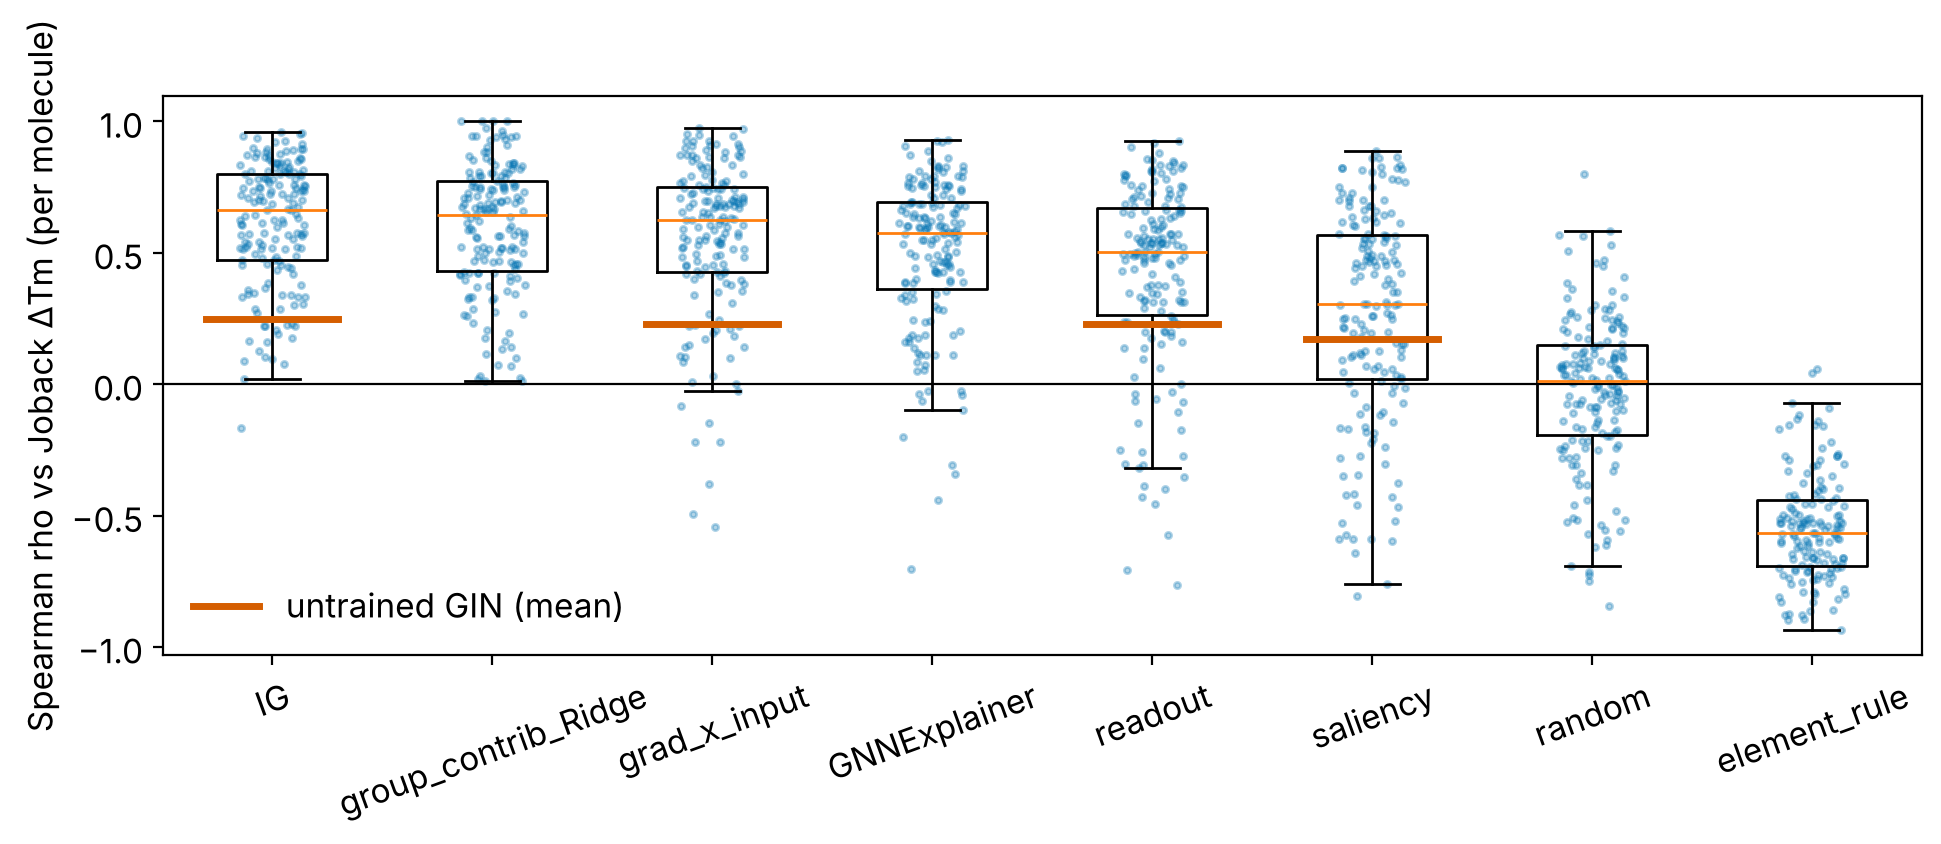

In [30]:
order = evj[evj.model == 'trained'].groupby('method').rho_signed.mean().sort_values(ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(10, 4))
data = [evj[(evj.model == 'trained') & (evj.method == m)].rho_signed.dropna().values for m in order]
ax.boxplot(data, showfliers=False); ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order, rotation=20)
for k, v in enumerate(data):
    ax.scatter(np.full(len(v), k + 1) + np.random.default_rng(k).uniform(-0.15, 0.15, len(v)), v, s=5, alpha=0.3, color='#0072B2')
un = evj[evj.model == 'untrained'].groupby('method').rho_signed.mean()
for k, m in enumerate(order):
    if m in un.index:
        ax.plot([k + 0.7, k + 1.3], [un[m]] * 2, color='#D55E00', lw=2.5, label='untrained GIN (mean)' if 'untrained GIN (mean)' not in ax.get_legend_handles_labels()[1] else None)
ax.axhline(0, color='k', lw=0.8); ax.set_ylabel('Spearman rho vs Joback ΔTm (per molecule)'); ax.legend(frameon=False, loc='lower left')
plt.tight_layout(); fig.savefig(f'{OUTX}/X3_rho_vs_joback_boxplot.png', dpi=150); plt.show()


## X4. 화학 점검: 수소결합 공여 원자의 기여
1주차 SHAP 에서 NumHDonors ↑ → mp ↑ 였고 Joback 도 –OH, –NH₂, –COOH 에 큰 + 몫을 준다. GIN 원자 기여에서도 N–H · O–H 원자가 그 분자 안에서 **위쪽**(+ 쪽)에 오는지 본다.
지표: 공여 원자의 기여가 그 분자 원자 기여의 중앙값보다 큰 비율 (무작위면 약 0.5).


In [31]:
rows = []
for r in pool.itertuples():
    hb = mx.hbd_atoms(r.smiles)
    if not hb:
        continue
    for name in ['readout', 'IG', 'grad_x_input', 'GNNExplainer', 'saliency', 'random']:
        a = np.asarray(store[(r.i, name)])
        rows.append(dict(i=r.i, method=name, frac_above_median=float(np.mean(a[hb] > np.median(a))), frac_positive=float(np.mean(a[hb] > 0))))
    if r.joback_ok:
        a = ref_jb[r.i]; rows.append(dict(i=r.i, method='Joback', frac_above_median=float(np.mean(a[hb] > np.median(a))), frac_positive=float(np.mean(a[hb] > 0))))
hbd = pd.DataFrame(rows).groupby('method')[['frac_above_median', 'frac_positive']].mean().round(3)
hbd['n_mol'] = pd.DataFrame(rows).groupby('method').i.nunique()
hbd.to_csv(f'{OUTX}/X4_hbond_donor_check.csv'); RX['hbd_check'] = hbd.reset_index().to_dict('records')
hbd.sort_values('frac_above_median', ascending=False)


,frac_above_median,frac_positive,n_mol
method,,,
Joback,0.981,1.000,89
IG,0.744,0.933,105
readout,0.708,0.929,105
grad_x_input,0.706,0.781,105
GNNExplainer,0.679,1.000,105
random,0.533,0.545,105
saliency,0.510,1.000,105


## X5. seed 를 바꾸면 설명이 바뀌나 (seed 3개)
GIN: seed 42 (위 c 절), 7 (f-3 절), 123 (여기서 새로 학습). XGBoost: 42, 43 (f-3 절), 44.


In [32]:
model3, info3 = train_gnn(sets, scaler, pooling='sum', seed=123, epochs=150, patience_stop=20)
torch.save(model3.state_dict(), f'{OUTX}/gin_sum_seed123.pt'); RX['gin_seed123'] = info3
gins = {42: model, 7: model2, 123: model3}
pool_d = [d for d in sets['test'] if d.x.shape[0] >= 6][:N_EVAL]
rows = []
for d in pool_d:
    for name, f in [('IG', attr_integrated_gradients), ('readout', attr_readout), ('grad_x_input', attr_grad_input)]:
        a = {s: f(m, d) for s, m in gins.items()}
        for s1, s2 in [(42, 7), (42, 123), (7, 123)]:
            rows.append(dict(method=name, pair=f'{s1}-{s2}', rho=rank_agreement(a[s1], a[s2])))
seed3 = pd.DataFrame(rows).groupby(['method', 'pair']).rho.mean().unstack().round(3)
seed3['mean'] = seed3.mean(1).round(3)
xgb3 = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.5,
                    n_jobs=2, random_state=SEED + 2).fit(X['train'], y['train'])
shap3 = np.abs(shap.TreeExplainer(xgb3).shap_values(X['test'])).mean(0)
S = {42: imp.shap.values, 43: shap2, 44: shap3}
xr = []
for s1, s2 in [(42, 43), (42, 44), (43, 44)]:
    xr.append(dict(pair=f'{s1}-{s2}', rho_all=spearmanr(S[s1], S[s2]).correlation,
                   top10_overlap=len(set(np.argsort(-S[s1])[:10]) & set(np.argsort(-S[s2])[:10]))))
xr = pd.DataFrame(xr).round(3)
seed3.to_csv(f'{OUTX}/X5_gin_seed_rank_agreement.csv'); xr.to_csv(f'{OUTX}/X5_xgb_seed_shap_agreement.csv', index=False)
RX['seed3_gin'] = seed3.reset_index().to_dict('records'); RX['seed3_xgb'] = xr.to_dict('records')
RX['gin_test_MAE_by_seed'] = {42: info['test_MAE'], 7: info2['test_MAE'], 123: info3['test_MAE']}
print('GIN test MAE by seed:', RX['gin_test_MAE_by_seed']); print(xr); seed3


  epoch   0  val MAE 59.312  (2 s)


  epoch  20  val MAE 50.269  (35 s)


  epoch  40  val MAE 38.937  (68 s)


  epoch  60  val MAE 37.084  (102 s)


  epoch  80  val MAE 38.627  (137 s)


[train_gnn] seed 123, sum pool: test MAE 38.227, 94 epochs, 159 s


GIN test MAE by seed: {42: 38.0221, 7: 37.3684, 123: 38.2268}
    pair  rho_all  top10_overlap
0  42-43    0.980              9
1  42-44    0.982              8
2  43-44    0.979              9


pair,42-123,42-7,7-123,mean
method,,,,
IG,0.870,0.802,0.788,0.820
grad_x_input,0.757,0.676,0.679,0.704
readout,0.933,0.903,0.912,0.916


## X6. 설명이 틀린 분자 후보
기준 (test 분자 200개 중 Joback 으로 덮인 것): GIN 예측 오차, readout 설명의 Joback ρ, seed 42 vs 7 일치도를 한 표에 둔다.
'설명이 틀렸다' = (i) Joback 과 순위가 반대(ρ < 0) **이고** (ii) seed 를 바꾸면 설명이 달라지거나, 수소결합 공여 원자를 − 쪽으로 읽는 경우. 예측 오차가 큰 분자를 우선 본다.


In [33]:
rows = []
gin_pred = {d.smiles: p for d, p in zip(sets['test'], predict_gnn(model, sets['test'], scaler))}
for r in pool.itertuples():
    if not r.joback_ok:
        continue
    d_ = [d for d in sets['test'] if d.smiles == r.smiles][0]
    a42, a7 = store[(r.i, 'readout')], attr_readout(model2, d_)
    hb = mx.hbd_atoms(r.smiles)
    rows.append(dict(i=r.i, smiles=r.smiles, n_atoms=r.n_atoms, y=float(d_.y_raw), pred=float(gin_pred[r.smiles]),
                     err=float(gin_pred[r.smiles] - d_.y_raw), joback_tm=mx.joback_tm(r.smiles),
                     rho_readout_joback=rank_agreement(a42, ref_jb[r.i]), rho_IG_joback=rank_agreement(store[(r.i, 'IG')], ref_jb[r.i]),
                     rho_readout_seed=rank_agreement(a42, a7), n_hbd=len(hb),
                     hbd_readout_sign=float(np.mean(np.asarray(a42)[hb] > 0)) if hb else np.nan))
cand = pd.DataFrame(rows)
cand['abs_err'] = cand.err.abs()
cand.sort_values('abs_err', ascending=False).round(3).to_csv(f'{OUTX}/X6_explanation_candidates.csv', index=False)
flag = cand[(cand.rho_readout_joback < 0) & ((cand.rho_readout_seed < 0.5) | (cand.hbd_readout_sign < 0.5))]
print(f'후보 {len(cand)}개 중 기준 (i)+(ii) 만족 {len(flag)}개')
flag.sort_values('abs_err', ascending=False).head(12).round(2)


후보 166개 중 기준 (i)+(ii) 만족 1개


,i,smiles,n_atoms,y,pred,err,joback_tm,rho_readout_joback,rho_IG_joback,rho_readout_seed,n_hbd,hbd_readout_sign,abs_err
53,61,NCCCN/C=C/NCCCN,12,271.15,443.09,171.94,446.68,-0.46,0.52,-0.14,4,1.0,171.94


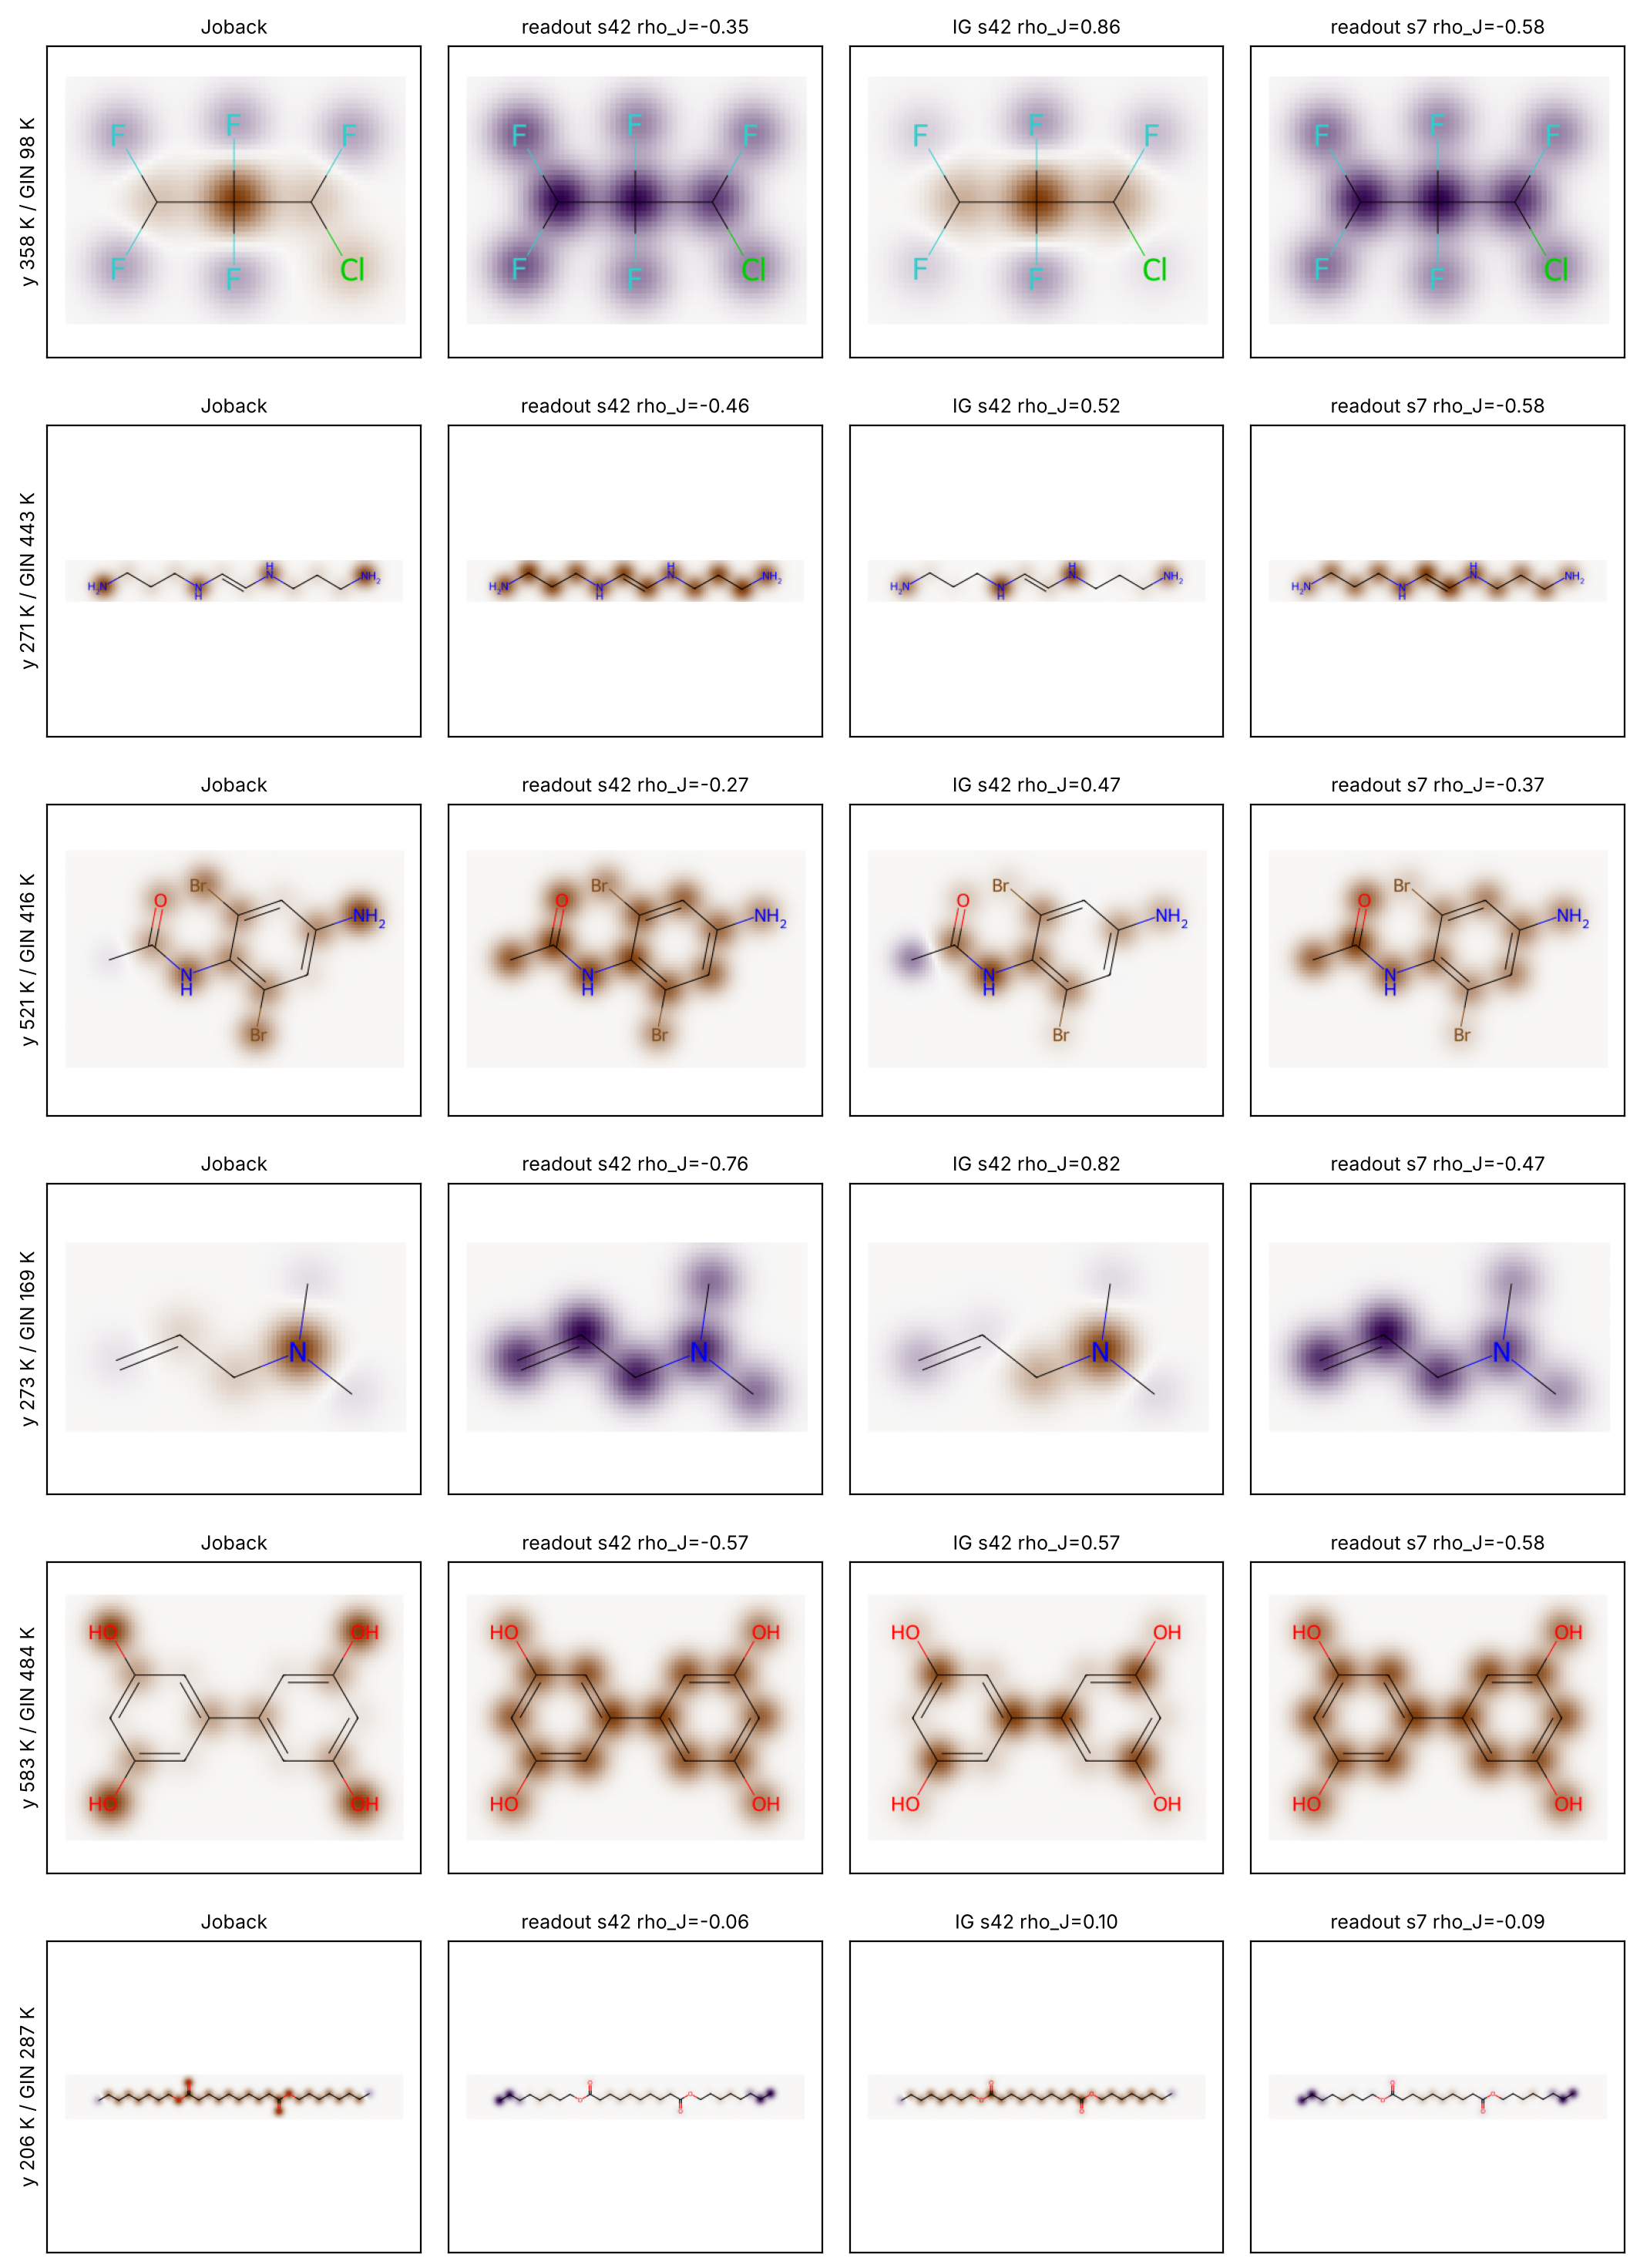

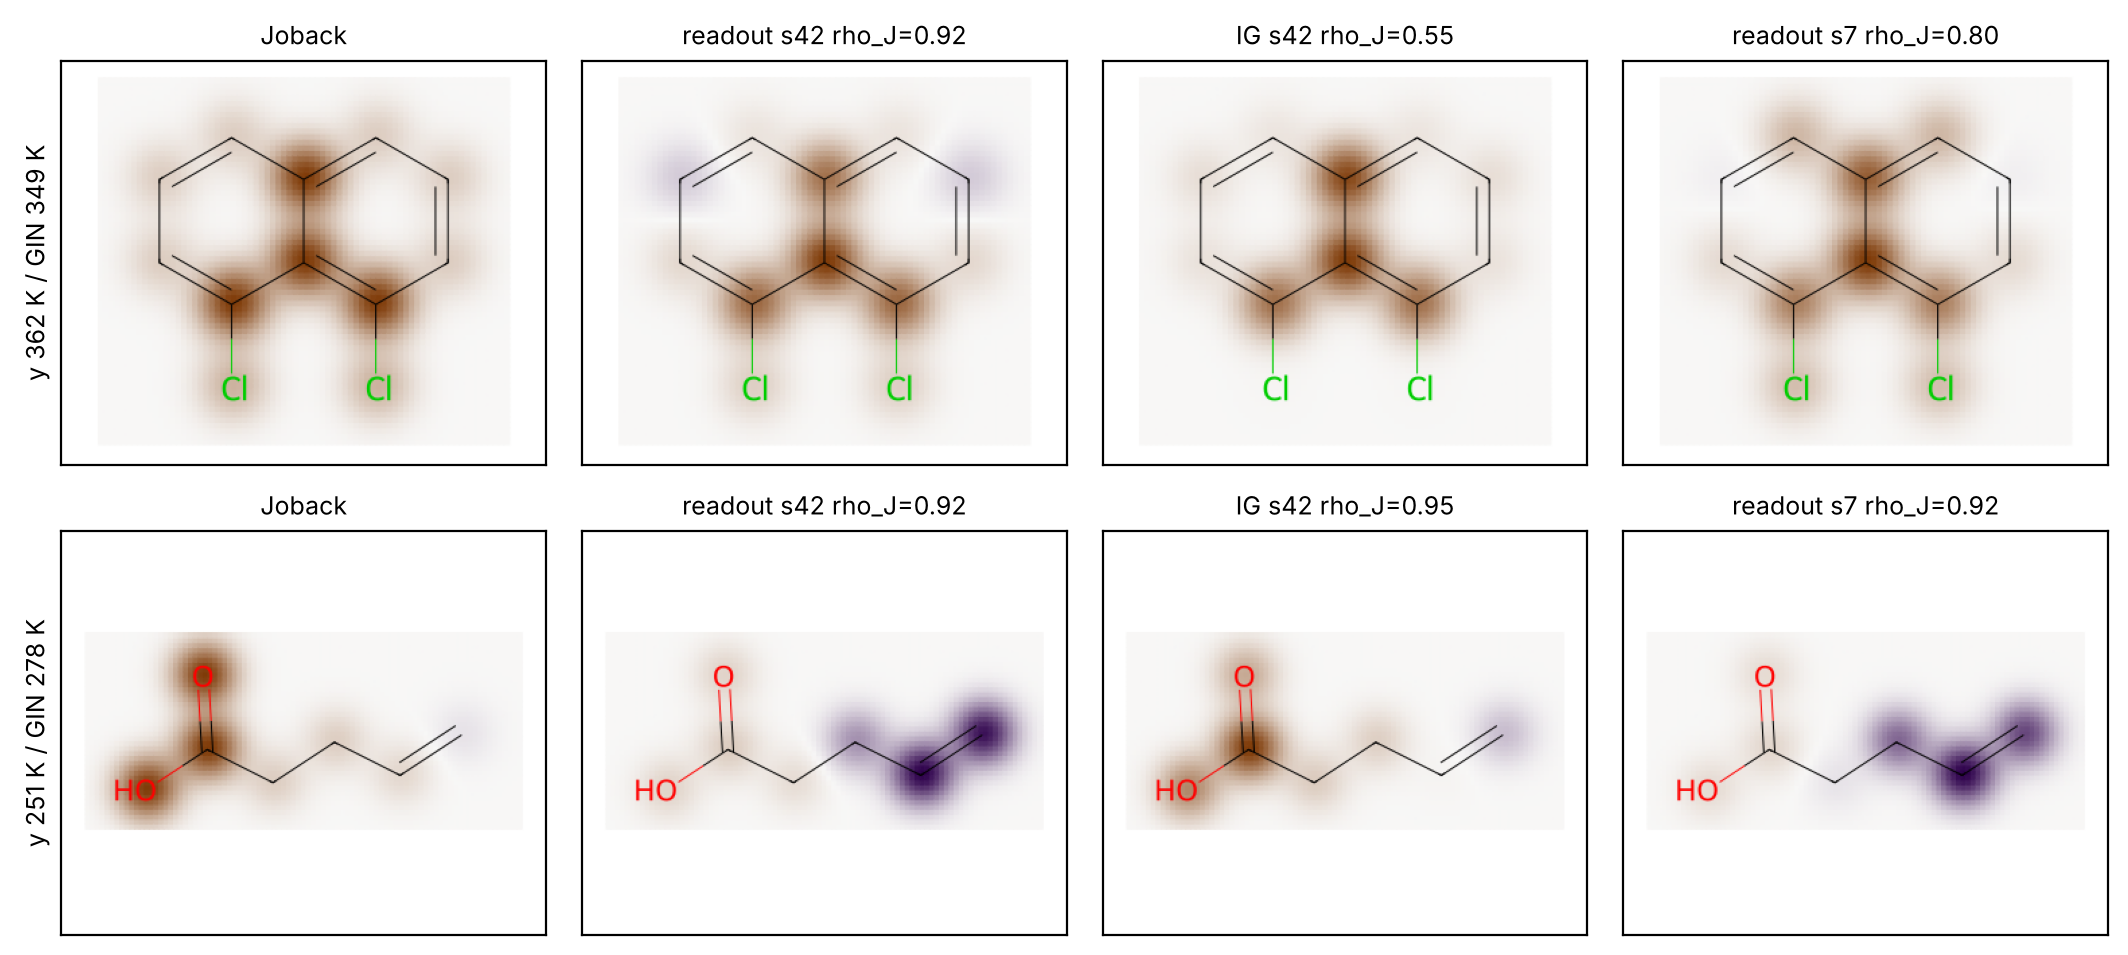

In [34]:
def draw_rows(rows_, fname, cols=('Joback', 'readout s42', 'IG s42', 'readout s7')):
    fig, axes = plt.subplots(len(rows_), len(cols), figsize=(2.7 * len(cols), 2.5 * len(rows_)))
    axes = np.atleast_2d(axes)
    for r_, rr in enumerate(rows_):
        d_ = [d for d in sets['test'] if d.smiles == rr.smiles][0]
        W = {'Joback': ref_jb[rr.i], 'readout s42': store[(rr.i, 'readout')], 'IG s42': store[(rr.i, 'IG')], 'readout s7': attr_readout(model2, d_)}
        for c_, m in enumerate(cols):
            ax = axes[r_, c_]; ax.imshow(png_to_array(atom_map_png(rr.smiles, W[m]))); ax.set_xticks([]); ax.set_yticks([])
            sub = '' if m == 'Joback' else f" rho_J={rank_agreement(W[m], ref_jb[rr.i]):.2f}"
            ax.set_title(m + sub, fontsize=9)
        axes[r_, 0].set_ylabel(f"y {rr.y:.0f} K / GIN {rr.pred:.0f} K", fontsize=9)
    plt.tight_layout(); fig.savefig(fname, dpi=150); plt.show()

src_ = flag if len(flag) >= 2 else cand.sort_values('rho_readout_joback').head(20)   # 기준을 만족하는 분자가 2개 미만이면 ρ 가 가장 낮은 20개에서
show_rows = list(src_.sort_values('abs_err', ascending=False).head(6).itertuples())
draw_rows(show_rows, f'{OUTX}/X6_wrong_explanation_candidates.png')
# 비교용: Joback 과 가장 잘 맞는 분자 2개 (원자 6–20개)
good = cand[cand.n_atoms.between(6, 20)].sort_values('rho_readout_joback', ascending=False).head(2)
draw_rows(list(good.itertuples()), f'{OUTX}/X6_good_explanation_examples.png')


## X7. 1주차 가설 확인 (validate 로): mean → sum readout 이 작은·비고리 분자에서 나아지나
1주차 후분석(test)에서 'GIN 은 작은 비고리 분자에서 크게 틀린다 → sum readout' 가설을 세웠다 (xai_notes 4절). test 를 보고 고르지 않으려고 **validate 500개**에서 확인한다.
같은 학습 함수(`train_gnn`, seed 42)로 mean 모델을 하나 더 학습해 sum(위 c 절)과 비교한다.


In [35]:
model_mean, info_mean = train_gnn(sets, scaler, pooling='mean', seed=SEED, epochs=150, patience_stop=20)
torch.save(model_mean.state_dict(), f'{OUTX}/gin_mean_seed{SEED}.pt'); RX['gin_mean_seed42'] = info_mean
yv = y['validate']
pv = {'mean': predict_gnn(model_mean, sets['validate'], scaler), 'sum': predict_gnn(model, sets['validate'], scaler)}
mols = [Chem.MolFromSmiles(s) for s in smi['validate']]
nat = np.array([m.GetNumAtoms() for m in mols]); ring = np.array([m.GetRingInfo().NumRings() for m in mols])
groups = {'전체': np.ones(len(yv), bool), '원자 ≤ 10': nat <= 10, '원자 11–20': (nat > 10) & (nat <= 20), '원자 > 20': nat > 20,
          '비고리': ring == 0, '비고리 & 원자 ≤ 10': (ring == 0) & (nat <= 10), 'mp < 250 K': yv < 250, 'mp > 500 K': yv > 500}
vt = pd.DataFrame({g: {'n': int(m.sum()), 'mean MAE': np.mean(np.abs(pv['mean'][m] - yv[m])), 'sum MAE': np.mean(np.abs(pv['sum'][m] - yv[m])),
                       'mean 평균잔차': np.mean(pv['mean'][m] - yv[m]), 'sum 평균잔차': np.mean(pv['sum'][m] - yv[m])} for g, m in groups.items()}).T
vt['sum − mean'] = vt['sum MAE'] - vt['mean MAE']
vt = vt.round(1); vt.to_csv(f'{OUTX}/X7_validate_mean_vs_sum.csv'); RX['validate_mean_vs_sum'] = vt.reset_index().to_dict('records')
print('test MAE (참고, 마지막에만 봄): mean', info_mean['test_MAE'], '/ sum', info['test_MAE'])
vt


  epoch   0  val MAE 51.754  (2 s)


  epoch  20  val MAE 42.330  (37 s)


  epoch  40  val MAE 36.011  (73 s)


[train_gnn] seed 42, mean pool: test MAE 35.536, 54 epochs, 97 s
test MAE (참고, 마지막에만 봄): mean 35.5356 / sum 38.0221


,n,mean MAE,sum MAE,mean 평균잔차,sum 평균잔차,sum − mean
전체,500.0,34.7,35.0,-3.3,-3.1,0.3
원자 ≤ 10,128.0,35.3,35.6,-0.5,2.2,0.3
원자 11–20,267.0,33.4,32.8,-4.4,-7.8,-0.6
원자 > 20,105.0,37.3,39.8,-4.0,2.3,2.4
비고리,80.0,35.3,37.4,-5.8,-2.0,2.1
비고리 & 원자 ≤ 10,55.0,35.9,38.5,-0.5,1.8,2.5
mp < 250 K,52.0,31.3,40.0,16.8,19.9,8.8
mp > 500 K,50.0,63.0,57.6,-59.8,-53.5,-5.4


In [36]:
RX['runtime_sec_total'] = round(time.time() - T0, 1)
json.dump(RX, open(f'{OUTX}/xai_mp_ext_summary.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1, default=float)
print(f"전체 {RX['runtime_sec_total']:.0f} s | 저장 폴더 {OUTX}:", sorted(os.listdir(OUTX)))


전체 1188 s | 저장 폴더 results_xai_mp_ext: ['X1_joback_vs_gin_parity.png', 'X1_mae_with_joback.csv', 'X2_shap_top10_compare.csv', 'X2_shap_top10_random_189desc.csv', 'X2_shap_top10_random_217desc.csv', 'X2_shap_top10_scaffold_189desc.csv', 'X3_rho_vs_joback_boxplot.png', 'X3_rho_vs_joback_per_molecule.csv', 'X3_rho_vs_joback_summary.csv', 'X4_hbond_donor_check.csv', 'X5_gin_seed_rank_agreement.csv', 'X5_xgb_seed_shap_agreement.csv', 'X6_explanation_candidates.csv', 'X6_good_explanation_examples.png', 'X6_wrong_explanation_candidates.png', 'X7_validate_mean_vs_sum.csv', 'gin_mean_seed42.pt', 'gin_sum_seed123.pt', 'gin_sum_seed42.pt', 'gin_sum_seed7.pt', 'xai_mp_ext_summary.json']
